# Defined Functions

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
from scipy import stats
import os
import string
import seaborn as sns
import textwrap

# Read .txt file into a df with proper heading, etc

def readtxt(filename):
    """Reads ref values from a .ref.txt file
    Args:
        filename (str): Name of .ref.txt file
    Returns:
        pd.Dataframe: contents of .ref.txt file
    """
    data = pd.read_csv(filename, delimiter="\t", header=0, index_col="Wavelength", dtype=float)
    return data

# Average and std deviation along horizontal axis (same wavelenth)
def mean_std_col(df):
    """Creates a mean and standard deviation column in the given dataframe from all data columns

    Args:
        df (pd.DataFrame): input dataframe

    Returns:
        pd.DataFrame: the same dataframe with an added mean and std columns
    """
    df_dropped = df.copy()

    if 'mean' in df_dropped.keys().tolist():
        df_dropped = df_dropped.drop(columns=['mean'])
    if 'std' in df_dropped.keys().tolist():
        df_dropped = df_dropped.drop(columns=['std'])
    
    mean_col = df_dropped.mean(axis=1)
    std_col = df_dropped.std(axis=1)

    if len(df_dropped.keys()) < 2:
        std_col[:] = np.nan

    df_dropped['mean'] = mean_col
    df_dropped['std'] = std_col

    return df_dropped

def mean_quartile_col(df):
    """Creates a mean and standard deviation column in the given dataframe from all data columns

    Args:
        df (pd.DataFrame): input dataframe

    Returns:
        pd.DataFrame: the same dataframe with an added mean, 1st, and 3rd quartile columns
    """
    df_dropped = df.copy()

    if 'mean' in df_dropped.keys().tolist():
        df_dropped = df_dropped.drop(columns=['mean'])
    if 'std' in df_dropped.keys().tolist():
        df_dropped = df_dropped.drop(columns=['std'])
    
    mean_col = df_dropped.mean(axis=1)
    first_col = df_dropped.quantile(0.25,axis=1)
    third_col = df_dropped.quantile(0.75,axis=1)


    if len(df_dropped.keys()) < 2:
        first_col[:] = np.nan
        third_col[:] = np.nan

    df_dropped['mean'] = mean_col
    df_dropped['1st'] = first_col
    df_dropped['3rd'] = third_col


    return df_dropped
        

# Consider taking out noise from 1831-1927 and 2452 and 2500 nm

def drop_rows(df):
    """Sets the x range for mean and std columns of the given data frame. Use for graphing 

    Args:
        df (pd.Dataframe): input dataframe
    """   
    try: 
        dr1 = np.arange(1820,1933,1).tolist()
        dr2 = np.arange(2452,2501,1).tolist()
        dr3 = np.arange(1355,1408,1).tolist()
        dr = dr1 + dr2 + dr3
        for row in dr:
            df.loc[row] = np.nan

        df.reindex(pd.Index(np.arange(350,2501,1)), name='Wavelength')
    except:
        1
        # print("There are no mean or std columns in the dataframe")

def drop_all_rows(df):
    """Sets the x range for all columns of the given data frame. Use for regression or stat analysis

    Args:
        df (pd.Dataframe): input dataframe
    """   
    try: 
        # pd.options.mode.chained_assignment = None  # Disable the warning
        dr1 = np.arange(1820,1933,1).tolist()
        dr2 = np.arange(2452,2501,1).tolist()
        dr3 = np.arange(1355,1408,1).tolist()
        dr = dr1 + dr2 + dr3
        for row in dr:
            df.loc[row] = np.nan
        df = df.dropna()
        # pd.options.mode.chained_assignment = 'warn' # Re-enable the warning (default)

        return df

    except:
        print()


# Graph with Y (ref) axis from 0-1 and X (wavelenth) along whole range
# fig,ax = plt.subplots(2,2)

def graph_reflectance(fig,ax,df,data_title):
    """Graphs reflectance data from a given data frame

    Args:
        fig (plt.fig): The already created figure to put line on
        ax (plt.axis): The already created axis to put line on
        df (pd.DataFrame): The dataframe from which the mean column will be graphed
        data_title (str): Name of the line that will go into the legend
    """    

    line, = ax.plot(df['mean'],
                    linewidth=1 # default line width. Consider going smaller
                    )
    line.set_label(data_title)
    ax.set_ylim(0,1)
    ax.set_ylabel("Reflectance")
    ax.set_xlim(350,2500)
    fig.supxlabel("Wavelength (nm)")
    ax.legend(fontsize='x-small',fancybox=False,shadow=False,
              loc='upper right',
              frameon=False,
            #   framealpha=1,edgecolor="black"
              )
    ax.tick_params(direction="in")

def graph_sd(fig,ax,df,data_title):
    """Graphs the standard deviation column of the given data frame

    Args:
        fig (plt.fig): The already created figure to put line on
        ax (plt.axis): The already created axis to put line on
        df (pd.DataFrame): The dataframe from which the std column will be graphed
        data_title (str): Name of the line that will go into the legend
    """    
    line, = ax.plot(df['std'],'--',
                    linewidth=1 # default line width. Consider going smaller
                    )
    line.set_label(data_title + "_sd")
    # ax.set_ylim(0,1)
    # ax.set_ylabel("Standard Deviation")
    # ax.set_xlim(350,2500)
    # fig.supxlabel("Wavelength (nm)")
    ax.legend(fontsize='x-small',fancybox=False,shadow=False,
              loc='upper right',
              frameon=False,
            #   framealpha=1,edgecolor="black"
              )
    ax.tick_params(direction="in")


    # ax.annotate(
    #     '1361',                                           # Annotation text
    #     xy=(1361, 0.8),                                   # Point to annotate
    #     xytext=(1361, 0.05),                              # Position of the text
    #     arrowprops=dict(facecolor='black', width=0.1),    # Arrow properties
    #     fontsize=10,
    #     color='black'
    # )

# list_dic['Jul18-blue-1.txt'].



def savefig(name = 'high_def_fig.png', p = 'C:\\Users\\nmmas\\OneDrive - Desert Research Institute\\Soil Reflectance\\Saved Graphs'):
    """Saves a high definition image

    Args:
        name (str): name of image (optional)
        p (str): path string of the folder where the image will be saved (optional)
    """    
    if '.' in name:
        plt.savefig(f'{p}\\{name}', dpi=1200, bbox_inches='tight')
    else:
        plt.savefig(f'{p}\\{name}.png', dpi=1200, bbox_inches='tight')




# Nested Dictionary Graphing

## Create Nested Dictionary

In [5]:
# Define universal constants
lineformats = {
                'blue':['blue','6 cm deep burned soil'],
               'green':['green','Repellent layer'],
               'grey':['grey','Charred layer'],
               'pink':['red','3 cm deep burned soil'],
               'white':['black','Ash'],
               'below2in':['brown','Below 5 cm unburned'],
               'top2in':['orange','Top 5 cm unburned']
               }

# wavelengths = [500,700,1000,2200]
# wavelengths = [355, 2000, 2250, 2400]

# Sentinel 2A bands:
wavelengths = [442,492,559,664,704,
               740,782,842,864,945,
               #1373, # this is removed by atmospheric noise. Only band not used.
               1613,2202]

# wavelengths = [442, 704, 842, 2202]


# order = ['pink','blue','white','grey','green','top2in','below2in']

# ash, char, rep, 3 cm, 6 cm, top2in, below2in
order = ['white','grey','green','pink','blue','top2in','below2in']



order_names = []
for my_type in order:
    order_names = order_names + [lineformats[my_type][1]]


style_default = 'default'

plt.style.use(style_default)


# sns.choose_diverging_palette()
map_seaborn = sns.diverging_palette(h_neg=248, h_pos=10, s=75, l=50, sep=128, as_cmap=True)

color_cb = ['#4477AA','#EE6677','#228833','#CCBB44','#66CCEE','#AA3377']
color_cb = ['#EE7733','#0077BB','#33BBEE','#CC3311','#009988','#bbbbbb']

color_cb = ['#aaaaaa','#CC3311','#0077BB','#33BBEE','#009988']


# Nested dictionaries
files_dic = {}
foldername = rf"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Jul1"

fig_dic = {}
ax_dic = {}
extra_figs = {}

for i in [4,5,6,7,8]:
    os.chdir(foldername + f"{i}")
    listdir = os.listdir()
    listdir = [txt for txt in listdir if txt.endswith(".txt")]

    files_dic[f'Jul1{i}'] = listdir


allsamples_dic = {}
for dic in files_dic.keys():
    os.chdir(foldername + f"{dic[-1:]}")
    allsamples_dic[dic] = {}
    for dir in files_dic[dic]:
        try:
            df = pd.read_csv(dir, delimiter="\t", header=0, index_col="Wavelength", dtype=float)
            allsamples_dic[dic][dir] = df
        except Exception as e:
                print(f"Error reading {dir}: {e}")

     
# Print data structure
# for x,y in allsamples_dic.items():
#     print("Fire:",x)
#     # print("\t",end="")
#     for key, value in y.items():
#         print(f"\t{key}")
#         print("\t\t",end='')
#         for key2,value2  in value.items():
#              print(key2, end=',')
#         print()
#     print()






# Sort out sample types into another sub dictionary




# Take the mean and standard deviation of each sample and store it in the same dataframe
for date,sample_list in allsamples_dic.items():
    for sample_name, sample_df in sample_list.items():
        if sample_name not in lineformats.keys():
            allsamples_dic[date][sample_name] = mean_std_col(sample_df)



color_list = list(mcolors.TABLEAU_COLORS.values())

letters = string.ascii_lowercase


# Create dataframe dictionary that holds a dataframe for each sample type
for date,sample_list in allsamples_dic.items():
    types_in_date = []
    for sample_name in sample_list.keys():
        for m in lineformats.keys():
            if m in sample_name:
                types_in_date.append(m)

    for my_type in types_in_date:
        allsamples_dic[date][my_type] = {}


for date,sample_list in allsamples_dic.items():
    for sample_name, sample_df in sample_list.items():
        for my_type in lineformats.keys():
            if my_type in sample_name:
                if my_type != sample_name:
                    allsamples_dic[date][my_type][sample_name]=sample_df

# Create dataframe in sample type specific dictionary that holds all data
for date,sample_list in allsamples_dic.items():
    for my_type in lineformats.keys():
        if my_type in sample_list.keys():
            allsamples_dic[date][my_type][f"{my_type}_all"] = pd.DataFrame()

    
    for my_type in lineformats.keys():
        df_list = []
        if my_type in sample_list:
            for s_name,s in sample_list[my_type].items():
                if s_name != f"{my_type}_all" and s_name != f"{my_type}_means":
                    df_list.append(s_name)
            
        dfs = [allsamples_dic[date][my_type][name] for name in df_list]
        if len(dfs) > 0:
            allsamples_dic[date][my_type][f"{my_type}_all"] = pd.concat(dfs, axis=1).drop(['mean','std'],axis=1)


# Pull mean columns out of individual samples and into a new df called {type}_means
#     Columns are called {sample_name}

for date,sample_list in allsamples_dic.items():
    for my_type in lineformats.keys():
        if my_type in sample_list.keys():
            allsamples_dic[date][my_type][f"{my_type}_means"] = pd.DataFrame()

    
    for my_type in lineformats.keys():
        df_list = []
        if my_type in sample_list:
            for s_name,s in sample_list[my_type].items():
                if s_name != f"{my_type}_all" and s_name != f"{my_type}_means":
                    df_list.append(s_name)
        # print(df_list)

        if len(df_list) > 0:
            temp_df = pd.DataFrame()
            for name in df_list:
                temp_df[name[:-4]] = allsamples_dic[date][my_type][name]['mean']

            allsamples_dic[date][my_type][f"{my_type}_means"] = temp_df

# Mean and std error columns
for date,sample_list in allsamples_dic.items():
    for my_type in lineformats.keys():
        if my_type in sample_list.keys():
            allsamples_dic[date][my_type][f'{my_type}_means'] = mean_std_col(allsamples_dic[date][my_type][f'{my_type}_means'])
            allsamples_dic[date][my_type][f'{my_type}_all'] = mean_std_col(allsamples_dic[date][my_type][f'{my_type}_all'])


# Create dfs for each sample type for all fires named sorted_dic[{type}]

sorted_dic = {}

for name in lineformats.keys():
    sorted_dic[name] = {}

for date,sample_list in allsamples_dic.items():
    for sample_name,sample in sample_list.items():
        for my_type in lineformats.keys():
            if my_type in sample_name:
                if sample_name is not my_type:
                    sorted_dic[my_type][sample_name] = sample.copy()



    # std deviation of observations
        # combine all observations into one df then do mean_std_col()

for my_type,type_dic in sorted_dic.items():

    df_list = []
    for sample_name,sample in type_dic.items():
        if sample_name != f"{my_type}_allobs" and sample_name != f"{type}_samplemeans": #change depending on later chosen names
            df_list.append(sample_name)

    if len(df_list) > 0:
        dfs = [sorted_dic[my_type][name] for name in df_list]
        sorted_dic[my_type][f"{my_type}_allobs"] = pd.concat(dfs,axis=1).drop(['mean','std'],errors='ignore',axis=1)
        sorted_dic[my_type][f"{my_type}_allobs"] = mean_std_col(sorted_dic[my_type][f"{my_type}_allobs"])


    # sample std error
        # [{type}_means].drop['mean','std] > all others
for my_type,type_dic in sorted_dic.items():

    df_list = []
    for sample_name,sample in type_dic.items():
        if sample_name != f"{my_type}_allobs" and sample_name != f"{my_type}_samplemeans": #change depending on later chosen names
            df_list.append(sample_name)


    if len(df_list) > 0:
        temp_df = pd.DataFrame()
        for name in df_list:
            temp_df[name[:-4]] = sorted_dic[my_type][name]['mean']

        sorted_dic[my_type][f"{my_type}_samplemeans"] = temp_df
        sorted_dic[my_type][f"{my_type}_samplemeans"] = mean_std_col(sorted_dic[my_type][f"{my_type}_samplemeans"])


    # fire std error
        # means of sample means per fire

for my_type,type_dic in sorted_dic.items():
    df_list = []

    for date,sample_list in allsamples_dic.items():
        for sample_name,sample in sample_list.items():
            if sample_name == my_type:
                df_list.append(date)

    if len(df_list) > 0:
        temp_df = pd.DataFrame()
        for date in df_list:
            temp_df[date] = allsamples_dic[date][f'{my_type}'][f'{my_type}_means']['mean'] 

    sorted_dic[my_type][f"{my_type}_firemeans"] = temp_df
    sorted_dic[my_type][f"{my_type}_firemeans"] = mean_std_col(sorted_dic[my_type][f"{my_type}_firemeans"])

sorted_dic['below2in']['below2in_firemeans'] = allsamples_dic['Jul18']['below2in']['below2in_means'].copy(deep=False)
sorted_dic['top2in']['top2in_firemeans'] = allsamples_dic['Jul18']['top2in']['top2in_means'].copy(deep=False)

sorted_dic['below2in']['below2in_samplemeans'] = allsamples_dic['Jul18']['below2in']['below2in_means'].copy(deep=False)
sorted_dic['top2in']['top2in_samplemeans'] = allsamples_dic['Jul18']['top2in']['top2in_means'].copy(deep=False)

# Create a copy of sorted_dic with dropped rows
import copy
sorted_dic_dropped = copy.deepcopy(sorted_dic)

new_index = pd.Index(np.arange(350,2501,1), name='Wavelength')

for my_type,sample_list in sorted_dic_dropped.items():
    for sample_name,sample in sample_list.items():
        sorted_dic_dropped[my_type][sample_name] = drop_all_rows(sample)

for my_type,sample_list in sorted_dic.items():
    for sample_name,sample in sample_list.items():
        drop_rows(sample)
        # df = sample.copy()
        # df = drop_rows(df)
        # sorted_dic[my_type][sample_name] = df#.reindex(new_index)

# pd.options.mode.chained_assignment = 'warn' # Re-enable the warning (default)
1


1

## Final Draft Graphs

blue [0, 1]
green [0, 1, 2]
grey [0, 2]
pink [0, 1]
white [0, 2]
below2in [0]
top2in [0, 2]


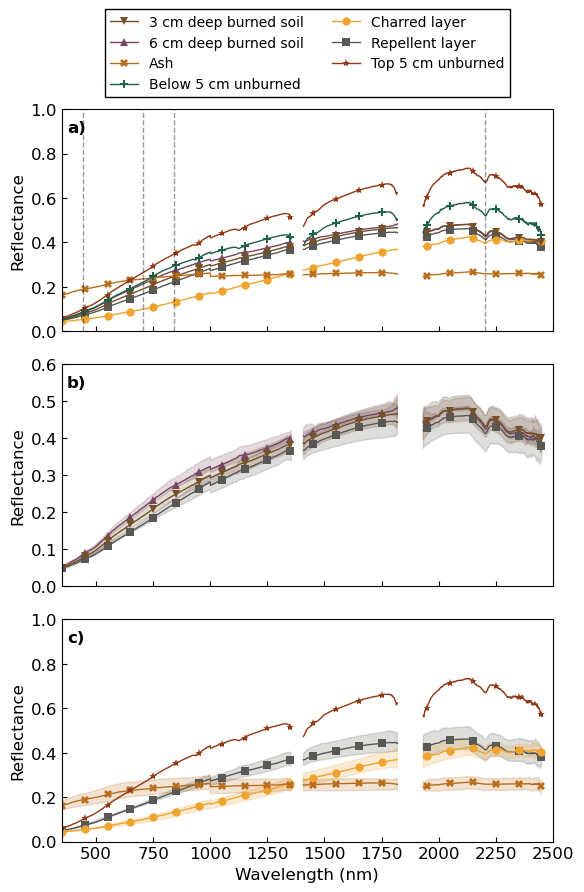

In [3]:
pal = ['#774762FF', '#BA6E1DFF', '#D6BB3BFF', '#755028FF', '#F2DD78FF', '#205F4BFF', '#913914FF', '#585854FF', '#F0A430FF', '#768048FF', '#800000FF', '#1B3A54FF']


lineformats_t = {
                'blue':[pal[0],'6 cm deep burned soil','^'],
               'green':[pal[7],'Repellent layer', 's'],
               'grey':[pal[8],'Charred layer','o'],
               'pink':[pal[3],'3 cm deep burned soil', 'v'],
               'white':[pal[1],'Ash', 'X'],
               'below2in':[pal[5],'Below 5 cm unburned','P'],
               'top2in':[pal[6],'Top 5 cm unburned','*']
               }


a = f'D_split'
plt.style.use(style_default)
plt.rcParams.update({'font.size': 12})

fig, axes = plt.subplots(3,1, figsize=(6,9), # change to 4,1, figsize=(6,9.6) when only 4 main sample types; 5,1, figsize=(6,12) otherwise
                        layout="tight", sharex=True
                        )

# fig.suptitle(f"Standard Error of All Samples")
# fig.supxlabel("Wavelength (nm)")
axes[2].set_xlabel("Wavelength (nm)")


for type,sample_list in sorted_dic.items():
    drop_rows(sorted_dic[type][f'{type}_samplemeans'])
    i_list = []

    if type in ['white','green','grey','pink','blue','top2in','below2in']:
        i_list.append(0)
    if type in ['blue','pink','green']:
        i_list.append(1)
    if type in ['top2in','green','white', 'grey']:
        i_list.append(2)
    # if type in ['pink','green']:
    #     i_list.append(3)

    print(type,i_list)

    df = mean_quartile_col(sample_list[f'{type}_samplemeans'])
    drop_rows(df)



    if len(i_list) > 0:
        for i in i_list:
            
            # Set axis titles:
            axes[i].set_ylim(0,1)
            axes[i].set_ylabel("Reflectance")
            axes[i].set_xlim(350,2500)
            axes[i].tick_params(direction="in")
        
            line, = axes[i].plot(df['mean'],
                        linewidth=1, # default line width. Consider going smaller
                        color=lineformats_t[type][0], markevery=100
                        )
            line.set_label(lineformats_t[type][1])
            line.set_marker(lineformats_t[type][2])
            line.set_markeredgewidth(0)
            # line.set_markersize(3)


        # Plot std deviation as error envelope
            if (i != 0):
                axes[i].fill_between(df.index, df['1st'], df['3rd'],
                                # df['mean'] - df['std'], 
                                # df['mean'] + df['std'], 
                                color=lineformats_t[type][0], alpha=0.2)
            
            # axes[i].legend(fontsize='x-small',fancybox=False,shadow=False,
            #             loc='upper left',
            #             frameon=False,
            #             #   framealpha=1,edgecolor="black"
            #             )

i=0

for ax in axes:

    
    
    ax.text(s=f'{letters[i]})', x=0.01,y=0.95,transform=ax.transAxes, weight='bold',
                    fontsize='medium', verticalalignment='top', fontfamily='sans serif'
                    # bbox=dict(facecolor='0.7', edgecolor='none', pad=3.0)
                )
    
    i+=1

ax = axes[0]
handles, labels = ax.get_legend_handles_labels()
sorted_labels_handles = sorted(zip(labels, handles), key=lambda x: x[0])
sorted_labels = [item[0] for item in sorted_labels_handles]
sorted_handles = [item[1] for item in sorted_labels_handles]

# 4. Pass the sorted handles and labels to ax.legend()
ax.legend(sorted_handles, sorted_labels,fancybox=False,shadow=False, ncols=2,fontsize=10,
                    loc='upper center', bbox_to_anchor=(0.5, 1.481),#bbox_to_anchor=(0.042, 0.981),
                    facecolor='w', edgecolor='k', framealpha=1)


for w in wavelengths:
    axes[0].vlines(w, ymin=0,ymax=1,color='#0006', linestyle='--', linewidth=1)


axes[1].set_ylim(0,0.6)
fig.tight_layout()

savefig('Spectra.jpg')

blue [0]
green [0]
grey [0]
pink [0]
white [0]
below2in [0]
top2in [0]


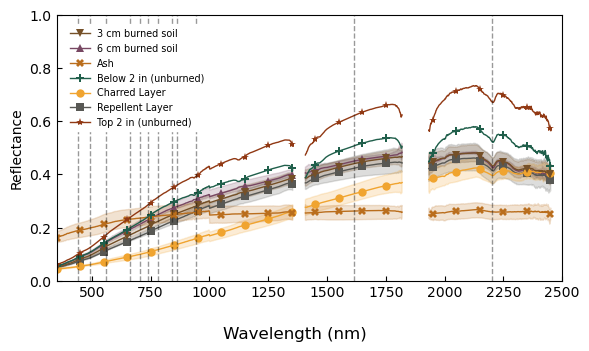

In [ ]:
pal = ['#774762FF', '#BA6E1DFF', '#D6BB3BFF', '#755028FF', '#F2DD78FF', '#205F4BFF', '#913914FF', '#585854FF', '#F0A430FF', '#768048FF', '#800000FF', '#1B3A54FF']


lineformats_t = {
                'blue':[pal[0],'6 cm deep burned soil','^'],
               'green':[pal[7],'Repellent layer', 's'],
               'grey':[pal[8],'Charred layer','o'],
               'pink':[pal[3],'3 cm deep burned soil', 'v'],
               'white':[pal[1],'Ash', 'X'],
               'below2in':[pal[5],'Below 5 cm unburned','P'],
               'top2in':[pal[6],'Top 5 cm unburned','*']
               }


a = f'D_split'
plt.style.use(style_default)

fig, axes = plt.subplots(1,1, figsize=(6,3.5), # change to 4,1, figsize=(6,9.6) when only 4 main sample types; 5,1, figsize=(6,12) otherwise
                        layout="tight", sharex=True
                        )

# fig.suptitle(f"Standard Error of All Samples")
fig.supxlabel("Wavelength (nm)")


for type,sample_list in sorted_dic.items():
    drop_rows(sorted_dic[type][f'{type}_samplemeans'])
    i_list = []

    if type in ['white','green','grey','pink','blue','top2in','below2in']:
        i_list.append(0)
    # if type in ['blue','pink','green']:
    #     i_list.append(1)
    # if type in ['top2in','green','white', 'grey']:
    #     i_list.append(2)
    # if type in ['pink','green']:
    #     i_list.append(3)

    print(type,i_list)

    df = mean_quartile_col(sample_list[f'{type}_samplemeans'])
    drop_rows(df)



    if len(i_list) > 0:

        
        # Set axis titles:
        axes.set_ylim(0,1)
        axes.set_ylabel("Reflectance")
        axes.set_xlim(350,2500)
        axes.tick_params(direction="in")
    
        line, = axes.plot(df['mean'],
                    linewidth=1, # default line width. Consider going smaller
                    color=lineformats_t[type][0], markevery=100
                    )
        line.set_label(lineformats_t[type][1])
        line.set_marker(lineformats_t[type][2])
        line.set_markeredgewidth(0)
        # line.set_markersize(3)


    # Plot std deviation as error envelope
        # if (i != 0):
        axes.fill_between(df.index, df['1st'], df['3rd'],
                        # df['mean'] - df['std'], 
                        # df['mean'] + df['std'], 
                        color=lineformats_t[type][0], alpha=0.2)
        
        axes.legend(fontsize='x-small',fancybox=False,shadow=False,
                    loc='upper left',
                    frameon=False,
                    #   framealpha=1,edgecolor="black"
                    )


handles, labels = axes.get_legend_handles_labels()
sorted_labels_handles = sorted(zip(labels, handles), key=lambda x: x[0])
sorted_labels = [item[0] for item in sorted_labels_handles]
sorted_handles = [item[1] for item in sorted_labels_handles]

# 4. Pass the sorted handles and labels to ax.legend()
axes.legend(sorted_handles, sorted_labels, fontsize='x-small',fancybox=False,shadow=False,
                    loc='upper left', bbox_to_anchor=(0.01, 0.981),
                    facecolor='w', edgecolor='w', framealpha=1)

# axes.text(s=f'{letters[i]})', x=0.01,y=0.95,transform=axes.transAxes, weight='bold',
#                 fontsize='medium', verticalalignment='top', fontfamily='sans serif'
#                 # bbox=dict(facecolor='0.7', edgecolor='none', pad=3.0)
#             )



for w in wavelengths:
    axes.vlines(w, ymin=0,ymax=1,color='#0006', linestyle='--', linewidth=1)


savefig('spectra_a.jpg')



# Ratios between fires summarized in heat maps

## Individual wavelength

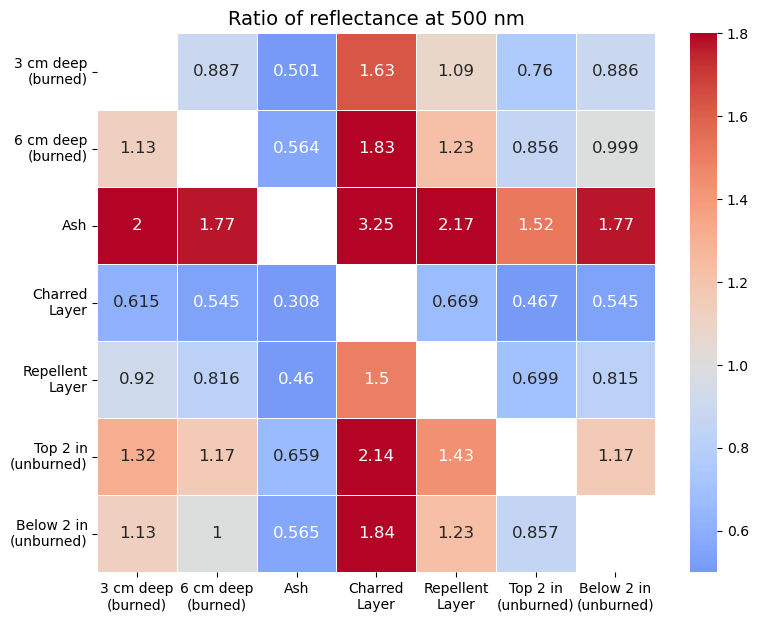

In [66]:
n = 500
plt.style.use(style_default)

df = pd.DataFrame()

for my_type,sample_list in sorted_dic.items():
  df[lineformats[my_type][1]] = sample_list[f'{my_type}_firemeans']['mean']

# Find a df with sample means of each datatype for each fire

row = df.loc[n]
row = row.reindex(order_names)

ratio_matrix = np.outer(row, 1 / row)

columns = row.index
df_ratios = pd.DataFrame(ratio_matrix,index = columns, columns = columns)

mask = np.zeros_like(df_ratios, dtype=bool)
mask[np.triu_indices_from(mask)] = True
np.fill_diagonal(mask, False)

maskdiag = np.zeros_like(df_ratios, dtype=bool)
# maskdiag[np.triu_indices_from(maskdiag)] = True
np.fill_diagonal(maskdiag, True)


fig, ax = plt.subplots(1,1, figsize = (9,7))
plt.title(f"Ratio of reflectance at {n} nm", fontsize=14)

heatmap = sns.heatmap(df_ratios, annot = True,
                      annot_kws = {'fontsize':12},
                      fmt='.3g',
                      linewidths=0.5,
                      cmap='coolwarm',
                    #   mask=mask, # the mask has been included here
                      mask = maskdiag,
                      ax=ax,
                      center = 1, vmax = 1.8, vmin = 0.5)

# Customize x-axis labels
x_labels = [textwrap.fill(label.get_text(), 12) for label in ax.get_xticklabels()]
ax.set_xticklabels(x_labels, rotation=0, ha="center")

# Customize y-axis labels
y_labels = [textwrap.fill(label.get_text(), 12) for label in ax.get_yticklabels()]
ax.set_yticklabels(y_labels, rotation=0, ha="right")

plt.show()

## Multiple wavelength grid

In [6]:
wavelengths

[442, 492, 559, 664, 704, 740, 782, 842, 864, 945, 1613, 2202]

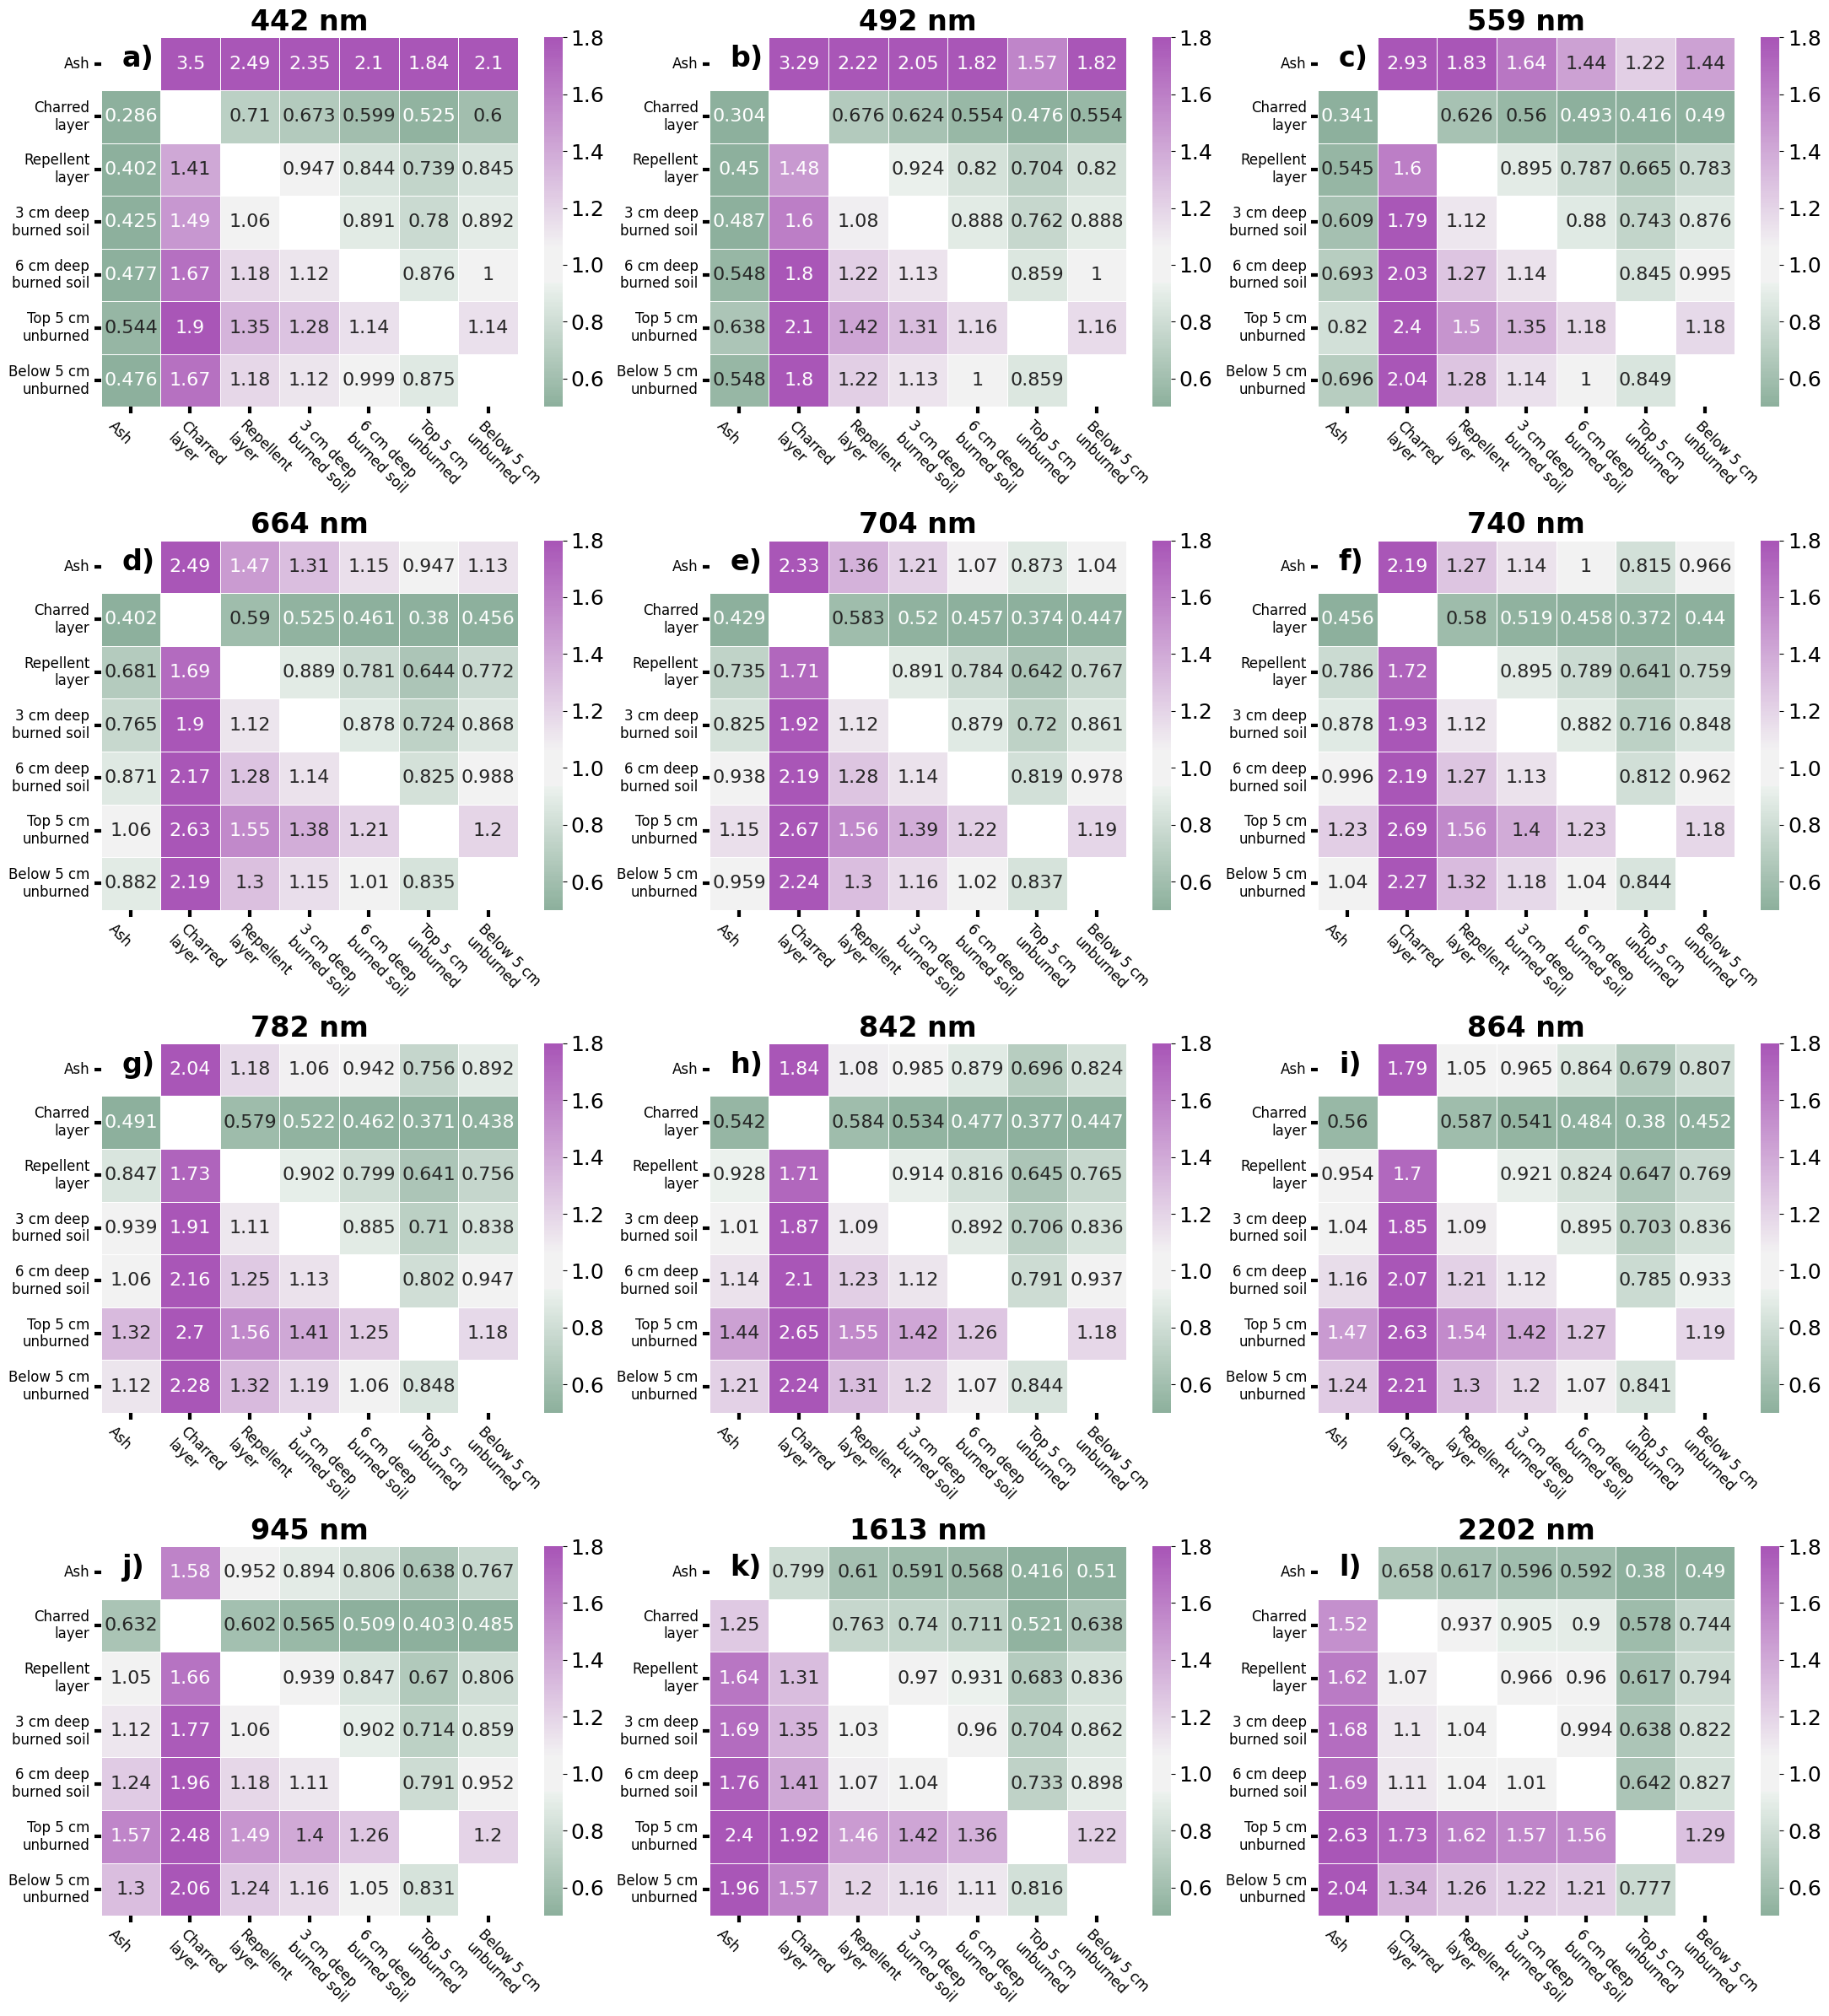

In [11]:

df = pd.DataFrame()
plt.style.use(style_default)


cp = sns.diverging_palette(145, 300, sep=20,s=60, as_cmap=True)


for my_type,sample_list in sorted_dic.items():
    df[lineformats[my_type][1]] = sample_list[f'{my_type}_firemeans']['mean']

# fig,axes = plt.subplots(2,2, figsize=(18,16), layout = 'tight') #gridspec_kw=dict(height_ratios=[9,9],width_ratios=[7,7]),
# ax_flat = axes.flatten()

fig,axes = plt.subplots(4,3, figsize=(22,24), layout = 'tight')
ax_flat = axes.flatten()

# fig, axes = plt.subplots(3,1,figsize=(9,20),layout='tight')
w = wavelengths

# Find a df with sample means of each datatype for each fire
for i,ax in enumerate(ax_flat):
    # n = wavelengths[i]
    n = w[i]


    row = df.loc[n]
    row = row.reindex(order_names)

    ratio_matrix = np.outer(row, 1 / row)

    columns = row.index
    df_ratios = pd.DataFrame(ratio_matrix,index = columns, columns = columns)

    mask = np.zeros_like(df_ratios, dtype=bool)
    mask[np.triu_indices_from(mask)] = True
    np.fill_diagonal(mask, False)

    maskdiag = np.zeros_like(df_ratios, dtype=bool)
    # maskdiag[np.triu_indices_from(maskdiag)] = True
    np.fill_diagonal(maskdiag, True)


    # fig, ax = plt.subplots(1,1, figsize = (9,7))
    ax.set_title(f"{n} nm", fontsize=24, fontweight="bold")

    ax.text(s=f'{letters[i]})', x=0.05,y=0.92,transform=ax.transAxes, 
            fontsize=24, fontweight="bold")

    heatmap = sns.heatmap(df_ratios, annot = True,
                        annot_kws = {'fontsize':16},
                        fmt='.3g',
                        linewidths=0.5,
                        cmap=cp,
                        #   mask=mask, # lower triangle mask
                        mask = maskdiag, # everything except diagonal mask
                        ax=ax,
                        center = 1, 
                        vmax = 1.8, vmin = 0.5) #change these vals to change color map range

    # use matplotlib.colorbar.Colorbar object to format color bar
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=18)

    # Customize x-axis labels
    x_labels = [textwrap.fill(label.get_text(), 12) for label in ax.get_xticklabels()]
    ax.set_xticklabels(x_labels, rotation=-45, ha="left", va='top', fontsize=12)

    # Customize y-axis labels
    y_labels = [textwrap.fill(label.get_text(), 12) for label in ax.get_yticklabels()]
    ax.set_yticklabels(y_labels, rotation=0, ha="right", fontsize=12)

    ax.tick_params(direction='out', length=6, width=3, colors='k')

    # create offset in x direction
    from matplotlib.transforms import ScaledTranslation
    dx, dy = -30, 0
    offset = ScaledTranslation(dx / fig.dpi, dy / fig.dpi, fig.dpi_scale_trans)

    # apply offset to all xticklabels
    for label in ax.xaxis.get_majorticklabels():
        label.set_transform(label.get_transform() + offset)

# savefig('grid_4_2.svg')
savefig('grid_all_.jpg')

plt.show()

# Ridgeline Graphing
adapted from https://python-graph-gallery.com/ridgeline-graph-seaborn/

In [41]:
# sorted_dic['pink']['pink_allobs'].loc[700]
sns.set_theme(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})

i = wavelengths
# del type
# sorted_dic['blue']['blue_allobs'].loc[i].drop(['mean','std'], axis=1)


allobs_df = pd.DataFrame()
# allobs_df[i] = np.nan

rows = []

for my_type,sample_list in sorted_dic.items():
    row = sample_list[f'{my_type}_allobs'].loc[i].drop(['mean','std'], axis=1).T
    row['s_type'] = my_type
    rows = rows + [row]

allobs_df = pd.concat(rows,axis=0)

# allobs_df['s type'] = [my_type.split('-')[-1] for my_type in allobs_df.index]

a = allobs_df.loc['Jul14-unburned-below2in00000.asd.ref':'Jul14-unburned-below2in00006.asd.ref'].index.to_list()
b = allobs_df.loc['Jul14-unburned-top2in00000.asd.ref':'Jul14-unburned-top2in00005.asd.ref'].index.to_list()
allobs_df.drop(a, inplace=True)
allobs_df.drop(b, inplace=True)

allobs_df

Wavelength,442.0,704.0,842.0,2202.0,s_type
Jul14-blue-1-repeated00000.asd.ref,0.101382,0.246585,0.312447,0.488222,blue
Jul14-blue-1-repeated00001.asd.ref,0.101872,0.248689,0.314764,0.495695,blue
Jul14-blue-1-repeated00002.asd.ref,0.093694,0.228954,0.289890,0.446606,blue
Jul14-blue-1-repeated00003.asd.ref,0.084135,0.205804,0.260845,0.394374,blue
Jul14-blue-1-repeated00004.asd.ref,0.080483,0.195695,0.249457,0.370845,blue
...,...,...,...,...,...
Jul18-unburned-top2in00004.asd.ref,0.103137,0.272966,0.362114,0.698798,top2in
Jul18-unburned-top2in00005.asd.ref,0.109109,0.290725,0.383923,0.694046,top2in
Jul18-unburned-top2in00006.asd.ref,0.106428,0.282042,0.374894,0.743600,top2in
Jul18-unburned-top2in00007.asd.ref,0.107558,0.285461,0.379446,0.757297,top2in


[11.25  5.25]
[11.25  5.25]
[11.25  5.25]
[11.25  5.25]


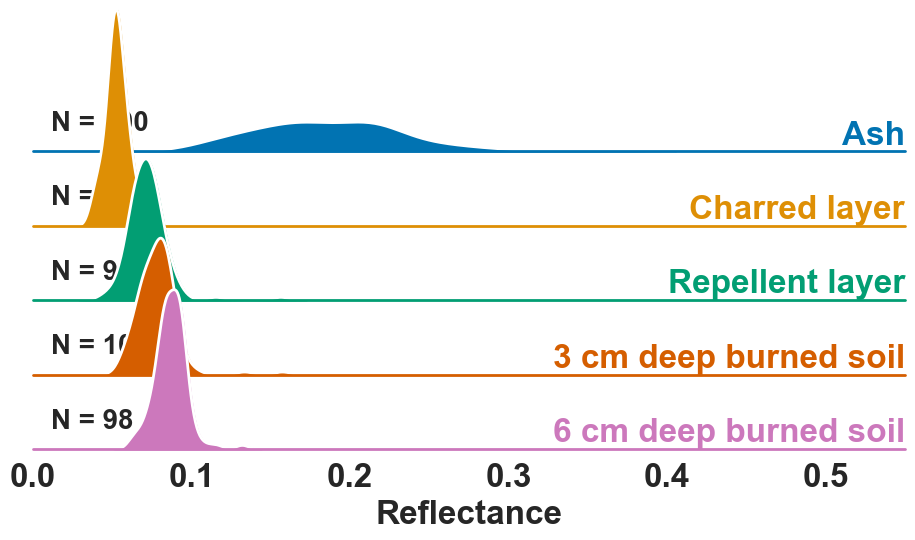

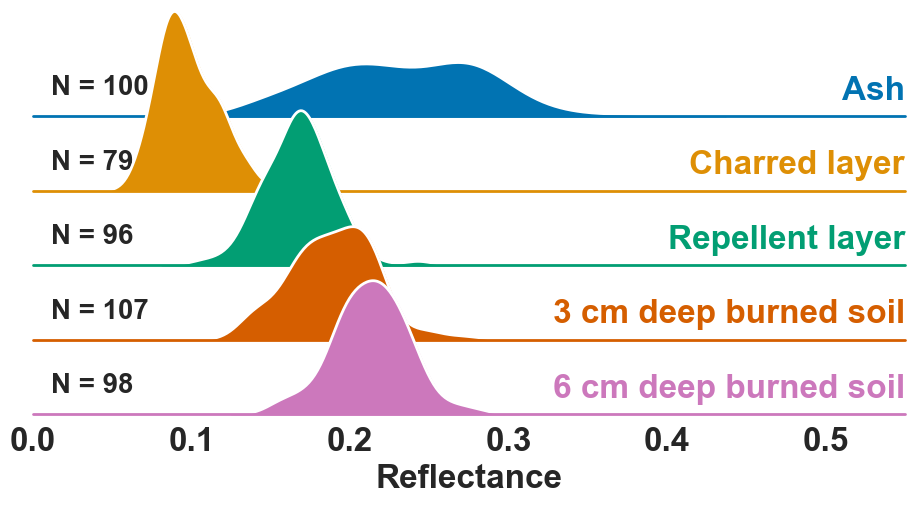

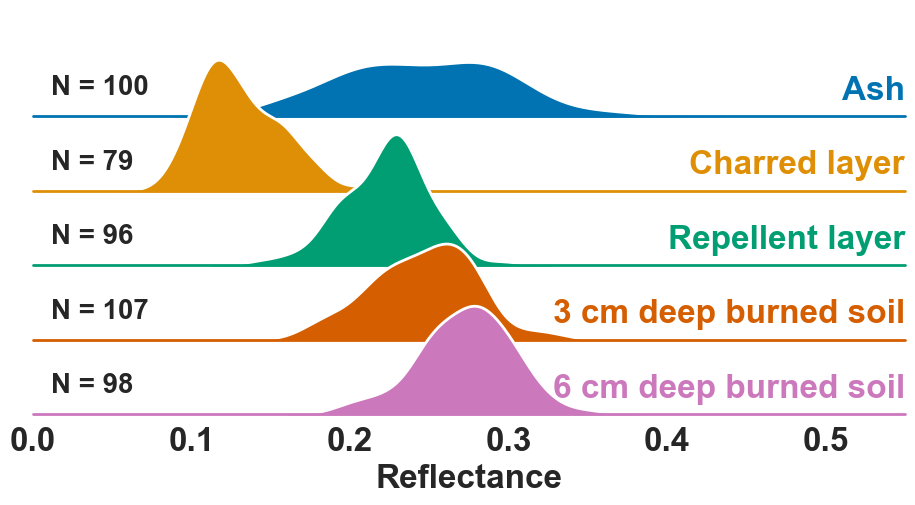

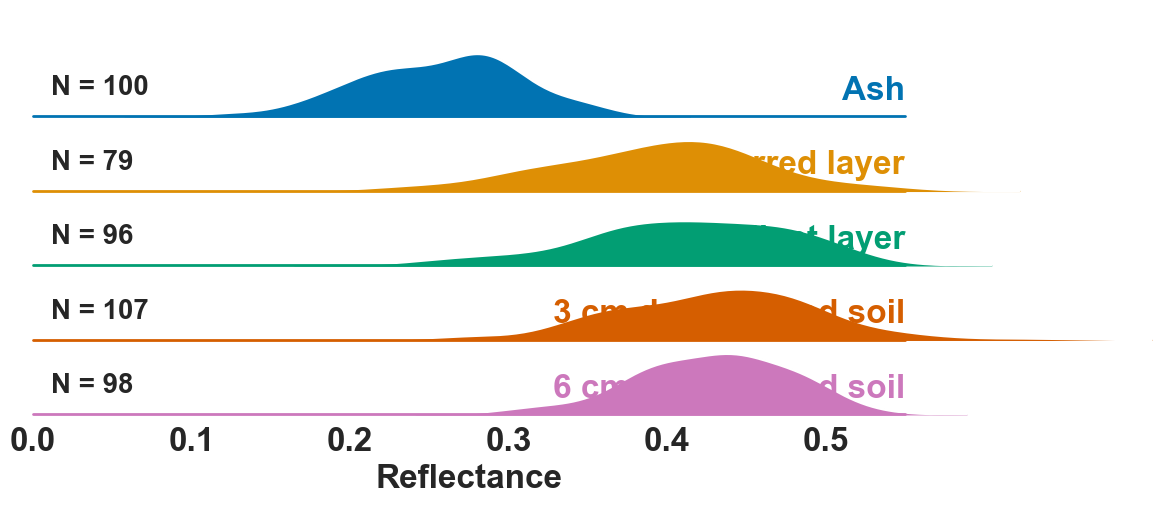

In [46]:
wavelength = wavelengths
wavelength = [442,704,842,2202]
sns.set_theme(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})

ylim_dict = dict(zip(wavelength, [(0,28),(0,13), (0,13), (0,13)]))



n=0

for w in wavelength:


      # we generate a color palette with Seaborn.color_palette()
      pal = sns.color_palette(palette='colorblind', n_colors=7)

      # in the sns.FacetGrid class, the 'hue' argument is the one that is the one that will be represented by colors with 'palette'
      g = sns.FacetGrid(allobs_df, row='s_type', hue = 's_type', 
                        aspect=20, height=0.5, palette = pal,
                        row_order = order[:-2], hue_order = order[:-2])

      # then we add the densities kdeplots for each 
      g.map(sns.kdeplot, w,
            bw_adjust=1, clip_on=False,
            fill=True, alpha=1, linewidth=1, common_norm=False, clip=(0,1.0))#, cut=0)

      # here we add a white line that represents the contour of each kdeplot
      g.map(sns.kdeplot, w, 
            bw_adjust=1, clip_on=False, 
            color="w", lw=2, common_norm=False, clip=(0,1.0))#, cut=0)

      # here we add a horizontal line for each plot
      g.map(plt.axhline, y=0, xmin=0,xmax=1,
            lw=2, clip_on=False)


      # # we loop over the FacetGrid figure axes (g.axes.flat) and add the sample type as text with the right color
      # # notice how ax.lines[-1].get_color() enables you to access the last line's color in each matplotlib.Axes    

      # Add sample type label
      for i, ax in enumerate(g.axes.flat):
            ax.text(.55, 2, lineformats[order[i]][1],
                        fontweight='bold', fontsize=24,
                        color=ax.lines[-1].get_color(),
                        horizontalalignment='right')
            
      # annotate the number of samples
      def annotate(data, **kws):
            n = len(data)
            ax = plt.gca()
            ax.text(0.02, 0.2, f"N = {n}", transform=ax.transAxes, 
                        fontweight='bold',
                        fontsize=20, zorder=0)
      
      g.map_dataframe(annotate, annot_kws={"fontsize": 20})

      # g.map_dataframe(annotate)


      # we use matplotlib.Figure.subplots_adjust() function to get the subplots to overlap
      g.figure.subplots_adjust(hspace=-0.3)
      g.set(xlim = (-0.0,0.55), ylim = ylim_dict[w]) # Single plot
      # g.set(xlim = (-0.15,1), ylim = ylim_dict[w])  # 4 wavelength plot
      g.figure.set_size_inches(11.25,5.25)

      # eventually we remove axes titles, yticks and spines
      g.set_titles(row_template="",col_template="")
      g.set_axis_labels(" "," ")
      g.set(yticks=[])
      g.despine(bottom=True, left=True)

      # Label x axis
      plt.setp(ax.get_xticklabels(), fontsize=24, fontweight='bold')
      plt.xlabel('Reflectance', fontweight='bold', fontsize=24)

      # Add letters and wavelength labels
      
      # g.fig.suptitle(f'{letters[n]} )    {w} nm',
      #                ha='left', x=0.15,y=0.95,
      #             fontsize=20,
      #             fontweight=20)
      
      print(g.fig.get_size_inches())

      n+=1

      savefig(str(w) + ".svg")
      savefig(str(w) + ".jpg")

plt.show()

# T vs Ref correlation

## Create Reflectance measurement DF

R_dic = {For each wavelength:df}

Index: Fire (Jul14,...,Jul18)

Col: s_type (blue,green,...)




In [ ]:

r_dic = {}

for w in wavelengths:
    # create df to go into r_dic
    df = pd.DataFrame()

    for my_type, sample_list in sorted_dic.items():
        col = sample_list[f'{my_type}_firemeans'].drop(['mean','std'], axis = 1).loc[w]
        df[lineformats[my_type][1]] = col

    # Relabel and order columns
    df = df.reindex(order_names, axis=1)
    
    r_dic[f'{w}'] = df.drop(['Top 5 cm unburned','Below 5 cm unburned'], axis=1)





Jul14         NaN
Jul15    0.236966
Jul16    0.286318
Jul17    0.215303
Jul18    0.235341
Name: Ash, dtype: float64

## Read Temperature data

In [31]:
## Read Thermocouple Data

temp_dic = {}
day_list = [4,5,6,7,8]


for day in day_list:
    df = pd.read_csv(rf"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Thermocouple\Jul1{day}_T.csv", skiprows=2)

    # Strip whitespace from all column names
    df.columns = df.columns.str.strip()
    df = df.set_index('SN')
    # df = df.sort_index(axis=1)
    temp_dic[f'Jul1{day}'] = df

therm_max = pd.DataFrame()
max_loc = pd.DataFrame()

for day,data in temp_dic.items():
    row = pd.Series()
    row_loc = pd.Series()
    for key,col in data.items():
        max = col.max()
        max_l = col.idxmax()
        row[key] = max
        row_loc[key] = max_l
    
    therm_max[day] = row
    max_loc[day] = row_loc

therm_max = therm_max.T
max_loc = max_loc.T

therm_max = therm_max.reindex(temp_dic['Jul15'].keys(), axis = 1)
max_loc = max_loc.reindex(temp_dic['Jul15'].keys(), axis=1)

# Manually filtered bad data:
mask_therm = therm_max > 50
mask_therm.loc['Jul14',['T9','T10','T11','T12']] = False
mask_therm.loc['Jul16','T9'] = False
mask_therm['T9'] = False
mask_therm['T11'] =  False
mask_therm

therm_max_filtered = therm_max[mask_therm]




# Create an average of the two thermocouple maximums per distance and depth
pairs = {}
x=[['T1','T3'],['T2','T4'],['T5','T7'],['T6','T8'],['T9','T11'],['T10','T12']]
y=['(5,0)','(5,-3)','(10,0)','(10,-3)','(15,0)','(15,-3)'] #these will be the labels on the heat map. This is the order used

order_therm = [
    '(5,0)','(10,0)','(15,0)',
    '(5,-3)', '(10,-3)', '(15,-3)'
]

therm_dic = {
    '(5,0)':'r=5 cm surface',
    '(10,0)':'r=10 cm surface',
    '(15,0)':'r=15 cm surface',
    '(5,-3)':'r=5 cm -3 cm', 
    '(10,-3)':'r=10 cm -3 cm', 
    '(15,-3)':'r=15 cm -3 cm'
}



for n,label in enumerate(y):
    pairs[label] = x[n]

therm_max_avg = pd.DataFrame()
therm_max_max = pd.DataFrame()
therm_max_avg_filtered = pd.DataFrame()
therm_max_max_filtered = pd.DataFrame()

for label,pair in pairs.items():
    therm_max_avg[label] = therm_max[pair].mean(axis=1)
    therm_max_max[label] = therm_max[pair].max(axis=1)
    therm_max_avg_filtered[label] = therm_max_filtered[pair].mean(axis=1)
    therm_max_max_filtered[label] = therm_max_filtered[pair].max(axis=1)


therm_max_avg = therm_max_avg.reindex(order_therm, axis=1)
therm_max_avg = therm_max_avg.rename(columns=therm_dic)

therm_max_max = therm_max_max.reindex(order_therm, axis=1)
therm_max_max = therm_max_max.rename(columns=therm_dic)

therm_max_avg_filtered = therm_max_avg_filtered.reindex(order_therm, axis=1)
therm_max_avg_filtered = therm_max_avg_filtered.rename(columns=therm_dic)

therm_max_max_filtered = therm_max_max_filtered.reindex(order_therm, axis=1)
therm_max_max_filtered = therm_max_max_filtered.rename(columns=therm_dic)

therm_max_max_filtered = therm_max_max_filtered.dropna(how='all', axis = 1)
therm_max_avg_filtered = therm_max_avg_filtered.dropna(how='all', axis = 1)


max_temp_col = therm_max_max_filtered.max(axis=1)

# therm_max_avg_filtered['Maximum'] = max_temp_col
therm_max_max_filtered['Maximum'] = max_temp_col

temp_sums = pd.DataFrame()

temp_dic['Jul14']

for day, df in temp_dic.items():
    if day != "Jul14":
        temp_sums[day] = df.sum(axis=0)

temp_sums  = temp_sums.T
temp_sums_filtered = temp_sums[mask_therm]




## Create avg thermocouple dfs


temp_dic_filtered = temp_dic.copy()

temp_dic_filtered.pop('Jul14')

temp_dic_filtered['Jul15'] = temp_dic_filtered['Jul15'].drop(['T9','T11', 'T12'], axis = 1)
temp_dic_filtered['Jul16'] = temp_dic_filtered['Jul16'].drop(['T9','T11', 'T12'], axis = 1)
temp_dic_filtered['Jul18'] = temp_dic_filtered['Jul18'].drop(['T13','T14'], axis = 1)

# Define thermocouples for each depth
surface = ['T1','T3','T5','T7','T9','T11']
t3cm = ['T2','T4','T6','T8','T10','T12']

# Extract
therm_avgs_dic = {}

for day in temp_dic_filtered.keys():

    surface_valid = temp_dic_filtered[day].columns.intersection(surface)
    d_valid = temp_dic_filtered[day].columns.intersection(t3cm)

    s = temp_dic_filtered[day][surface_valid]
    d = temp_dic_filtered[day][d_valid]

    s_avg = s.mean(axis=1)
    d_avg = d.mean(axis=1)

    dic = {'Surface':s_avg, '3 cm':d_avg}

    df = pd.DataFrame(dic)

    therm_avgs_dic[day] = df

therm_avgs_dic['Jul15']




## Read iButton Data


os.chdir(rf"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\iButton Data")
file_list = os.listdir()

# Create iButton Data Nested Dictionary
ib_dic_1 = {} # for iButton 1
ib_dic_2 = {} # for iButton 2

ib_dic = {} # for iButton Averages by depth and day

for f in file_list:
    idf = pd.read_csv(f, header=0)

    # Strip whitespace from all column names
    idf.columns = idf.columns.str.strip()
    idf = idf.set_index('TimeCounter')

    d = "Jul"+str(int(f[-5]) + 13)    

    if '1_' in f:
        ib_dic_1[d] = idf
    if '2_' in f:
        if '15' in d:
            idf = idf.drop(columns=['Temp_5cm','Temp_10cm'])
        ib_dic_2[d] = idf


ib_dic_1['Jul15']

for day in ['Jul15','Jul16','Jul17','Jul18']:

    ib_dic[day] = {}

    for depth in ['Temp_5cm','Temp_10cm']:
        c1c = False
        c2c = False

        if depth in ib_dic_1[day].keys():
            c1 = ib_dic_1[day][depth]
            c1c = True
        if depth in ib_dic_2[day].keys():
            c2 = ib_dic_2[day][depth]
            c2c =  True

        if c1c and c2c:
            c = (c1 + c2) / 2
        elif c1c:
            c = c1
            print(day, depth)
        elif c2c:
            c = c2
            print(day, depth)
        

        depthx = depth.split('_')[-1]

        ib_dic[day][depthx] = c.dropna()
    
ib_6cm_dic = {}

for day in list(ib_dic.keys()):
    x = ib_dic[day]['10cm'] - 4/5 * (ib_dic[day]['10cm'] - ib_dic[day]['5cm'])
    x.name = day
    ib_6cm_dic[day] = x

ib_6cm = pd.DataFrame.from_dict(ib_6cm_dic, orient='columns')



## Integrate Over Temperature (first 360 minutes)
#Integrating from 0-360 minutes. There are some descrepencies with start times with this, 
#but its a good approximation of the heat into the soil at that depth

# Thermocouple sum dataframe (Surface and 3 cm)
therm_int_dic = {}

for key,day in therm_avgs_dic.items():
    therm_int_dic[key] = day.loc[0:360].sum()

therm_int = pd.DataFrame.from_dict(therm_int_dic).T

# iButton sum dataframe (6 cm)
ib_int = pd.Series(ib_6cm.loc[0:360].sum() * 10, name='6 cm')

# Temp sum df (Surface, 3 cm, and 6 cm)
temp_int = therm_int.join(ib_int)

temp_int = temp_int/60
temp_int


# Make a temperature max df from all thermocouples
depth_dic = {
    'T1':'Surface',
    'T3':'Surface',
    'T5':'Surface',
    'T7':'Surface',
    'T9':'Surface',
    'T11':'Surface',
    'T2':'3 cm',
    'T4':'3 cm',
    'T6':'3 cm',
    'T8':'3 cm',
    'T10':'3 cm',
    'T12':'3 cm'    
}

distance_dic = {
    'T1':5,
    'T3':5,
    'T5':10,
    'T7':10,
    'T9':15,
    'T11':15,
    'T2':5,
    'T4':5,
    'T6':10,
    'T8':10,
    'T10':15,
    'T12':15  
}

angle_dic = {

    'T1':0,
    'T3':20,
    'T5':90,
    'T7':110,
    'T9':180,
    'T11':200,
    'T2':5,
    'T4':25,
    'T6':95,
    'T8':115,
    'T10':185,
    'T12':205 

}

day_dic = {
    'Jul14':'July 14th',
    'Jul15':'July 15th',
    'Jul16':'July 16th',
    'Jul17':'July 17th',
    'Jul18':'July 18th'
}

temp_max_dic = {}

for date,df in temp_dic_filtered.items():
    t = temp_dic_filtered[date].max(axis=0)

    t = t.reset_index().rename(columns={'index':'Thermocouple',0:date})


    t = t.set_index('Thermocouple')


    temp_max_dic[date] = t

temp_max_df = pd.concat(temp_max_dic.values(), axis=1)

temp_max_df = temp_max_df.reset_index()

temp_max_df['Depth'] = temp_max_df['Thermocouple'].map(depth_dic)
temp_max_df['R'] = temp_max_df['Thermocouple'].map(distance_dic)

temp_max_df = temp_max_df.set_index(['Thermocouple','Depth','R'])
temp_max_df = temp_max_df.stack().reset_index().rename(columns={'level_3':'Date',0:'Max Temp'})
temp_max_df['Date'] = temp_max_df['Date'].map(day_dic)


# Add 6 cm iButton data to temp_max_df
t = ib_6cm.max().reset_index().rename(columns={'index':'Date',0:'Max Temp'})

t['Date'] = t['Date'].map(day_dic)

t['R'] = np.repeat(0,4)
t['Depth'] = np.repeat('6 cm',4)
t['Thermocouple'] = np.repeat('iButton',4)


temp_max_df = pd.concat([t,temp_max_df])

temp_max_df = temp_max_df.reset_index(drop=True)

temp_max_max_df = temp_max_df.groupby(['Depth','Date'])['Max Temp'].mean().reset_index()



# Create a df of how many minutes each thermocouple measured above temperatures
# temp_175C_counts_df
temp_175C_counts_dic = {}

for date,df in temp_dic_filtered.items():
    t = temp_dic_filtered[date][temp_dic_filtered[date] > 175].count(axis=0)

    t = t.reset_index().rename(columns={'index':'Thermocouple',0:date})


    t = t.set_index('Thermocouple')


    temp_175C_counts_dic[date] = t

temp_df = pd.concat(temp_175C_counts_dic.values(), axis=1)

temp_df = temp_df.reset_index()

temp_df['Depth'] = temp_df['Thermocouple'].map(depth_dic)
temp_df['R'] = temp_df['Thermocouple'].map(distance_dic)

temp_df = temp_df.set_index(['Thermocouple','Depth','R'])
temp_df = temp_df.stack().reset_index().rename(columns={'level_3':'Date',0:'Minutes Above 175C'})
temp_df['Date'] = temp_df['Date'].map(day_dic)

temp_175C_counts_df = temp_df.reset_index(drop=True)



# temp_200C_counts_df
temp_200C_counts_dic = {}

for date,df in temp_dic_filtered.items():
    t = temp_dic_filtered[date][temp_dic_filtered[date] > 200].count(axis=0)

    t = t.reset_index().rename(columns={'index':'Thermocouple',0:date})


    t = t.set_index('Thermocouple')


    temp_200C_counts_dic[date] = t

temp_df = pd.concat(temp_200C_counts_dic.values(), axis=1)

temp_df = temp_df.reset_index()

temp_df['Depth'] = temp_df['Thermocouple'].map(depth_dic)
temp_df['R'] = temp_df['Thermocouple'].map(distance_dic)

temp_df = temp_df.set_index(['Thermocouple','Depth','R'])
temp_df = temp_df.stack().reset_index().rename(columns={'level_3':'Date',0:'Minutes Above 200C'})
temp_df['Date'] = temp_df['Date'].map(day_dic)

temp_200C_counts_df = temp_df.reset_index(drop=True)

# temp_280C_counts_df
temp_280C_counts_dic = {}

for date,df in temp_dic_filtered.items():
    t = temp_dic_filtered[date][temp_dic_filtered[date] > 280].count(axis=0)

    t = t.reset_index().rename(columns={'index':'Thermocouple',0:date})


    t = t.set_index('Thermocouple')


    temp_280C_counts_dic[date] = t

temp_df = pd.concat(temp_280C_counts_dic.values(), axis=1)

temp_df = temp_df.reset_index()

temp_df['Depth'] = temp_df['Thermocouple'].map(depth_dic)
temp_df['R'] = temp_df['Thermocouple'].map(distance_dic)

temp_df = temp_df.set_index(['Thermocouple','Depth','R'])
temp_df = temp_df.stack().reset_index().rename(columns={'level_3':'Date',0:'Minutes Above 280C'})
temp_df['Date'] = temp_df['Date'].map(day_dic)

temp_280C_counts_df = temp_df.reset_index(drop=True)

# temp_400C_counts_df
temp_400C_counts_dic = {}

for date,df in temp_dic_filtered.items():
    t = temp_dic_filtered[date][temp_dic_filtered[date] > 400].count(axis=0)

    t = t.reset_index().rename(columns={'index':'Thermocouple',0:date})


    t = t.set_index('Thermocouple')


    temp_400C_counts_dic[date] = t

temp_df = pd.concat(temp_400C_counts_dic.values(), axis=1)

temp_df = temp_df.reset_index()

temp_df['Depth'] = temp_df['Thermocouple'].map(depth_dic)
temp_df['R'] = temp_df['Thermocouple'].map(distance_dic)

temp_df = temp_df.set_index(['Thermocouple','Depth','R'])
temp_df = temp_df.stack().reset_index().rename(columns={'level_3':'Date',0:'Minutes Above 400C'})
temp_df['Date'] = temp_df['Date'].map(day_dic)

temp_400C_counts_df = temp_df.reset_index(drop=True)

# temp_175_200C_counts_df
temp_175_200C_counts_dic = {}

for date,df in temp_dic_filtered.items():

    mask_175 = temp_dic_filtered[date] < 175
    mask_200 = temp_dic_filtered[date] > 200
    mask = ~(mask_175 + mask_200)

    t = temp_dic_filtered[date][mask].count(axis=0)

    t = t.reset_index().rename(columns={'index':'Thermocouple',0:date})


    t = t.set_index('Thermocouple')


    temp_175_200C_counts_dic[date] = t

temp_df = pd.concat(temp_175_200C_counts_dic.values(), axis=1)

temp_df = temp_df.reset_index()

temp_df['Depth'] = temp_df['Thermocouple'].map(depth_dic)
temp_df['R'] = temp_df['Thermocouple'].map(distance_dic)

temp_df = temp_df.set_index(['Thermocouple','Depth','R'])
temp_df = temp_df.stack().reset_index().rename(columns={'level_3':'Date',0:'Minutes 175-200C'})
temp_df['Date'] = temp_df['Date'].map(day_dic)

temp_175_200C_counts_df = temp_df.reset_index(drop=True)

# Combine into a single df
temp_counts_df = pd.merge(temp_175C_counts_df,temp_200C_counts_df)
temp_counts_df = pd.merge(temp_counts_df, temp_280C_counts_df)
temp_counts_df = pd.merge(temp_counts_df, temp_400C_counts_df)
temp_counts_df = pd.merge(temp_counts_df, temp_175_200C_counts_df)
temp_counts_df



# Create a df of temperature sums when each thermocouple measured above 175 C
# temp_175C_sums_df

temp_max_df




Jul15 Temp_5cm
Jul15 Temp_10cm
Jul17 Temp_5cm


,Date,Max Temp,R,Depth,Thermocouple
0,July 15th,93.692,0,6 cm,iButton
1,July 16th,111.100,0,6 cm,iButton
2,July 17th,120.780,0,6 cm,iButton
3,July 18th,91.572,0,6 cm,iButton
4,July 15th,429.300,5,Surface,T1
5,July 16th,342.400,5,Surface,T1
6,July 17th,416.000,5,Surface,T1
7,July 18th,495.300,5,Surface,T1
8,July 15th,127.200,5,3 cm,T2
9,July 16th,159.300,5,3 cm,T2


In [61]:
temp_counts_stacked = temp_counts_df.set_index(['Thermocouple','Depth','R','Date']).stack().reset_index()
temp_counts_stacked.rename(columns={'level_4':"Threshold",0:'Time'}, inplace=True)
temp_counts_stacked

scatter_data

,Date,Max Temp,R,Depth,Thermocouple
0,July 15th,93.692,0,6 cm,iButton
1,July 16th,111.100,0,6 cm,iButton
2,July 17th,120.780,0,6 cm,iButton
3,July 18th,91.572,0,6 cm,iButton


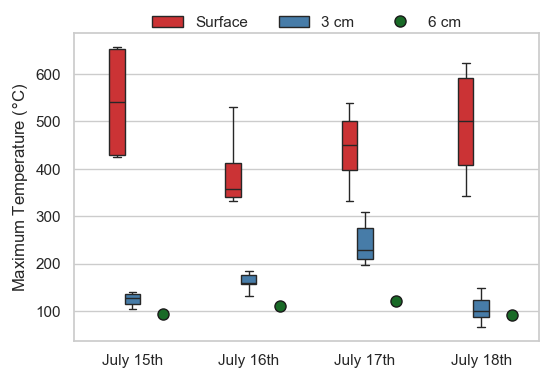

In [45]:
mask1 = temp_max_df['Depth'].str.contains('Surface')
mask2 = temp_max_df['Depth'].str.contains('3')

mask= mask1 + mask2



# box plot data
box_data = temp_max_df[temp_max_df['Depth'].isin(['Surface','3 cm'])]

# scatter data
scatter_data = temp_max_df[temp_max_df['Depth'] == '6 cm']




colors = sns.color_palette(palette='Set1', n_colors=2)
colors = list(colors) + ["#196A27FF"]


# temp_max_df[mask1].groupby('Date')['Max Temp'].mean()
sns.set_theme(style="whitegrid")
fig,ax = plt.subplots(1,1, figsize=(6,4))


# Create and display the plot
sns.boxplot(x="Date",
            y="Max Temp",
            hue="Depth", hue_order=['Surface','3 cm','6 cm'],
            data=box_data,#[mask],
            palette=colors,
            width=0.4, ax=ax,
             whis=(0, 100))

sns.stripplot(dodge=True,jitter=False,
    data=scatter_data,
    x="Date",
    y="Max Temp",
    hue="Depth",hue_order=['Surface','3 cm','6 cm'],
    palette=colors,
    s=8,
    linewidth=1,      
    edgecolor="k", 
)

handles, labels = ax.get_legend_handles_labels()

handles = [handles[i] for i in [0,1,-1]]
labels = [labels[i] for i in [0,1,-1]]

# handles[-1] = plt.Line2D([], [], color="#196A27FF", linestyle='', marker='o',
#                           label='6 cm')

ax.legend(handles, labels,
    loc='upper center', frameon=False, bbox_to_anchor=(.5,1.1), ncols=3)
ax.set_ylabel(r'Maximum Temperature ($\degree$C)')
ax.set_xlabel('')

savefig(name='temp_box_plt.jpg')

plt.show()

In [9]:
mask1 = temp_max_df['Depth'].str.contains('Surface')
t = temp_max_df[mask1]
mask2 = t['Date'].str.contains('17')

mask= mask1 + mask2

t[mask2]['Max Temp'].mean()

444.7833333333333

In [38]:
temp_counts_stacked[mask3]

,Thermocouple,Depth,R,Date,Threshold,Time
5,T1,Surface,5,July 16th,Minutes Above 175C,107.0
6,T1,Surface,5,July 16th,Minutes Above 200C,94.0
7,T1,Surface,5,July 16th,Minutes Above 280C,28.0
8,T1,Surface,5,July 16th,Minutes Above 400C,0.0
9,T1,Surface,5,July 16th,Minutes 175-200C,13.0
25,T2,3 cm,5,July 16th,Minutes Above 175C,0.0
26,T2,3 cm,5,July 16th,Minutes Above 200C,0.0
27,T2,3 cm,5,July 16th,Minutes Above 280C,0.0
28,T2,3 cm,5,July 16th,Minutes Above 400C,0.0
29,T2,3 cm,5,July 16th,Minutes 175-200C,0.0


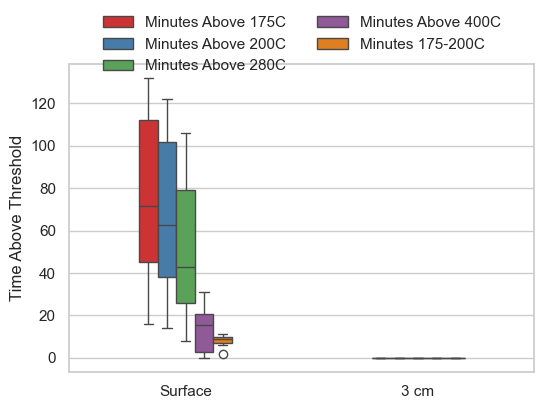

In [42]:
temp_counts_stacked = temp_counts_df.set_index(['Thermocouple','Depth','R','Date']).stack().reset_index()
temp_counts_stacked.rename(columns={'level_4':"Threshold",0:'Time'}, inplace=True)


mask1 = temp_counts_stacked['Depth'].str.contains('Surface')
mask2 = temp_counts_stacked['Depth'].str.contains('3')
mask3 = temp_counts_stacked['Date'].str.contains('July 18th')


mask= mask1 + mask2 + mask3


# temp_counts_df[mask1].groupby('Date')['Max Temp'].mean()
sns.set_theme(style="whitegrid")
fig,ax = plt.subplots(1,1, figsize=(6,4))

# temp_counts_df[mask1].boxplot(column='Max Temp', by='Date', ax=ax, grid=False)


# plt.show()


# Add a dark grid


# Create and display the plot
sns.boxplot(x="Depth",
            y="Time",
            hue="Threshold", #hue_order=['Surface','3 cm','6 cm'],
            data=temp_counts_stacked[mask3],
            palette="Set1",
            width=0.4, ax=ax)

handles, labels = ax.get_legend_handles_labels()

# handles[-1] = plt.Line2D([], [], color='k',
#                           label='6 cm')

ax.legend(handles, labels,
    loc='upper center', frameon=False, bbox_to_anchor=(.5,1.2), ncols=2)
ax.set_ylabel('Time Above Threshold')
ax.set_xlabel('')

savefig(name='temp_box_plt_j18.png')

plt.show()

In [80]:
mask1 = temp_counts_df['Depth'].str.contains('Surface')
mask2 = temp_counts_df['Depth'].str.contains('3')

mask3 = temp_counts_df['Date'].str.contains('16')
mask = ~(~mask3 + ~mask2)

temp_counts_df[mask2].describe().drop(columns=['R'])

temp_counts_df[mask]

,Thermocouple,Depth,R,Date,Minutes Above 175C,Minutes Above 200C,Minutes Above 280C,Minutes Above 400C,Minutes 175-200C
5,T2,3 cm,5,July 16th,0.0,0.0,0.0,0.0,0.0
13,T4,3 cm,5,July 16th,0.0,0.0,0.0,0.0,0.0
21,T6,3 cm,10,July 16th,56.0,0.0,0.0,0.0,57.0
29,T8,3 cm,10,July 16th,16.0,0.0,0.0,0.0,16.0
33,T10,3 cm,15,July 16th,0.0,0.0,0.0,0.0,0.0


## Plot Temperature Data

In [9]:
colors = sns.color_palette(palette='Set1', n_colors=2)
colors = list(colors) + ["#196A27FF"]

colors

[(0.8941176470588236, 0.10196078431372549, 0.10980392156862745),
 (0.21568627450980393, 0.49411764705882355, 0.7215686274509804),
 '#196A27FF']

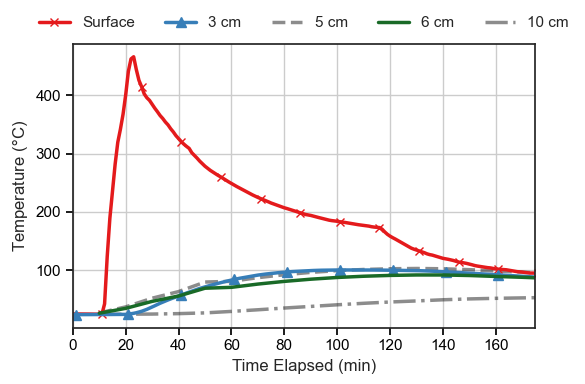

In [28]:
sns.set_theme(style="white")

fig, ax = plt.subplots(1,1, figsize=(6,4), sharex=True, sharey=True)

# colors=[ "#196A27FF","#412F0EFF", "#7A6F1CFF", 
#         "#74F3D3FF", "#751C6DFF", "#FDC067FF", 
#         "#AC9ECEFF", "#6EC5ABFF"]

colors = sns.color_palette(palette='Set1', n_colors=2)
colors = list(colors) + ["#196A27FF"]
lw = 2.5




day = ib_dic['Jul18'].copy()



ax.set_title(list(ib_dic.keys())[0][:-2] + 'y ' + list(ib_dic.keys())[0][-2:])#, fontsize=20)

x = day['5cm'].copy()
x.index = x.index #- 20
ax.plot(x, 'k--', alpha=0.5, label='5 cm', linewidth = lw,)
x = day['10cm'].copy()
x.index = x.index #- 20
ax.plot(x, 'k-.', alpha=0.5,label='10 cm', linewidth = lw,)


day = therm_avgs_dic['Jul18'].copy()
day.index = day.index - 20
ax.plot(day['Surface'], color=colors[0], label='Surface', linewidth = lw,
        marker='x', markevery=15, markersize=6)
ax.plot(day['3 cm'], color=colors[1], label='3 cm', linewidth = lw,
        marker='^', markevery=20, markersize=7)

x = ib_6cm['Jul18'].copy()

x.index = x.index #- 20

x.plot(ax=ax, subplots=True, color=colors[2], linewidth = lw,
       label='6 cm', legend=False)

handles, labels = ax.get_legend_handles_labels()

labels[-1] = '6 cm'

new_order = [2,3,0,4,1]
handles = [handles[i] for i in new_order]
labels = [labels[i] for i in new_order]


ax.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 1.0),
           fancybox=True, shadow=False, ncol=len(labels), frameon=False, #fontsize=15
           )


ax.set_xlabel('Time Elapsed (min)', )
              #fontsize=20)
ax.set_ylabel(r'Temperature ($\degree$C)')#, fontsize=20)
# ax.tick_params(labelsize=15, direction='out')
# # ax.set_xticks(np.arange(0,500,25))

ax.tick_params(axis='both', which='both', bottom=True, left=True, #labelsize=15,
               size=5, colors='black')

ax.set_title('')

ax.set_xlim(0,175)
ax.grid()

plt.tight_layout()

savefig(name='temp_j18_zoom.jpg')

fig.get_size_inches()

plt.show()


In [27]:
temp_max_df.set_index(['Date','Depth'])['Max Temp'].groupby(level=[0,1]).mean()#.groupby(level=[1]).mean()

Date       Depth  
July 15th  3 cm       124.180000
           6 cm        93.692000
           Surface    541.050000
July 16th  3 cm       161.540000
           6 cm       111.100000
           Surface    394.450000
July 17th  3 cm       242.466667
           6 cm       120.780000
           Surface    444.783333
July 18th  3 cm       104.983333
           6 cm        91.572000
           Surface    494.933333
Name: Max Temp, dtype: float64

c:\Users\nmmas\anaconda3\Lib\site-packages\seaborn\axisgrid.py:854: UserWarning: The palette list has more values (12) than needed (4), which may not be intended.
  func(*plot_args, **plot_kwargs)


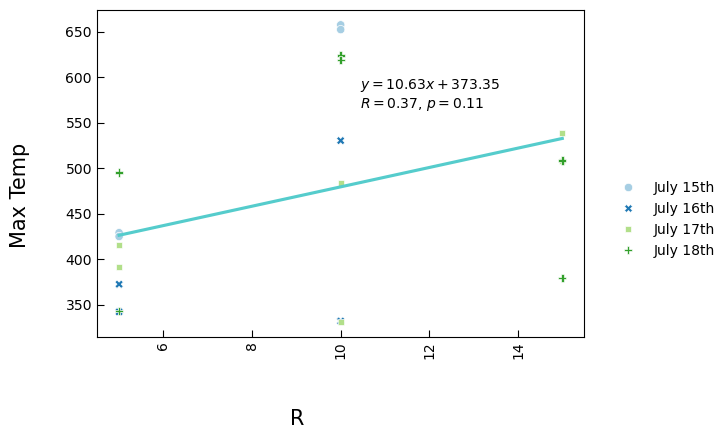

In [ ]:
df = temp_max_df.copy()


mask1 = (df['Depth'].str.contains('Surface'))
# mask2 = (df['Type'].str.contains('3 cm'))
# mask3 = (df['Type'].str.contains('6 cm'))


# mask = mask1 + mask2 + mask3

c = '#5cc'




g = sns.FacetGrid(df[mask1],height=4, aspect=1.5,
                  margin_titles=True, despine=False, sharex=False)#, hue='rep')
g.map_dataframe(sns.regplot, x='R', y="Max Temp", scatter = False, color=c, ci=None)
g.map_dataframe(sns.scatterplot, x='R', y="Max Temp", hue='Date',style='Date', 
                palette=sns.color_palette("Paired"))#, #'rocket'
                #hue_order = ['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'])




# # Add a black reg line for best fit (no ash or charred)
# def plot_filtered_regression(x, y, **kwargs):
#     # 'data' is passed via kwargs when using FacetGrid.map_dataframe
#     # Filter the data within the function scope for the current facet's data subset
#     current_facet_data = kwargs.pop('data')
#     subset_data = current_facet_data[mask]
#     sns.regplot(x=x, y=y, data=subset_data, scatter=False, ax=plt.gca(), **kwargs)

# g.map_dataframe(plot_filtered_regression, x='R', y="Max Temp", color='k', ci=None)


# Annotate black reg line (no ash or charred)
def annotate(data, **kws):
    slope, intercept, r_value, p_value, std_err = stats.linregress(data['R'], data['Max Temp'])

    ax = plt.gca()
    # ax.text(0.3, 0.27, 'r={:.2f}\np={:.2g}'.format(r, p),
    #         transform=ax.transAxes)

    ax.text(0.54,0.7, f'$y={slope:.2f}x{intercept:+.2f}$\n$R={r_value:.2f}$, $p=${p_value:.2g}',
            transform=ax.transAxes)
    
g.map_dataframe(annotate)



# # Annotate blue reg line (all sample types)
# def annotate(data, **kws):
#     slope, intercept, r_value, p_value, std_err = stats.linregress(data['NBR'], data['ACA per water droplet'])

#     ax = plt.gca()

#     ax.text(0.65,0.15, f'$y={slope:.2f}x{intercept:+.2f}$\n$R={r_value:.2f}$, $p=${p_value:.2g}',
#             transform=ax.transAxes, color='#099')
    
# g.map_dataframe(annotate)








g.set_axis_labels("", "")

g.fig.text(0.4, -0.06, 'R', ha='center', va='center', size=15)
g.fig.text(0.01, 0.5, 'Max Temp', ha='center', va='center', rotation='vertical', size=15)

g.set_titles(col_template="{col_name}", size=15)
g.tick_params(
    axis='both',
    which='major',
    length=5,
    direction='in'
)


g.figure.subplots_adjust(wspace=0, hspace=0)



for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(90)


g.add_legend()

plt.show()

### Other Fire Variables

Burn Time + Weight

In [ ]:
other_vars = pd.DataFrame()
other_vars['Burn Time (min)'] = {'Jul14':14,
                           'Jul15':22,
                           'Jul16':32,
                           'Jul17':22,
                           'Jul18':18
                        }

other_vars['Weight (kg)'] = {'Jul14':3.2,
                        'Jul15':2.9,
                        'Jul16':5.15,
                        'Jul17':4.85,
                        'Jul18':2.8
                        }



other_vars

,Burn Time (min),Weight (kg)
Jul14,14,3.20
Jul15,22,2.90
Jul16,32,5.15
Jul17,22,4.85
Jul18,18,2.80


# Read ACA data

In [37]:
filename = r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\ACA measurements for Summer 25 courtyard burns - 11-10-25.xlsx"

aca_df = pd.read_excel(filename)

aca_df

aca_df[['Date','Sample']] = aca_df['Sample type'].str.split(' - ', expand=True)

aca_df['ACA per water droplet'] = aca_df['ACA per water droplet'].mask(aca_df['ACA per water droplet']=='<10', other=10) # other=10
aca_df['ACA per water droplet'] = aca_df['ACA per water droplet'].astype('float')

aca_df[['Type','rep']] = aca_df['Sample'].str.split(' rep ', expand=True)

# fix names of sample types to align
aca_df['Type'] = aca_df['Type'].mask(aca_df['Type'].str.contains('below'), other='Unburned below 2in')
aca_df['Type'] = aca_df['Type'].mask(aca_df['Type'].str.contains('top'), other='Unburned top 2in')
aca_df['Type'] = aca_df['Type'].mask(aca_df['Type'].str.contains('charr'), other='Charred layer')
aca_df['Type'] = aca_df['Type'].mask(aca_df['Type'].str.contains('ash'), other='Ash')
aca_df['Type'] = aca_df['Type'].mask(aca_df['Type'].str.contains('3 cm'), other='3 cm deep burned soil')
aca_df['Type'] = aca_df['Type'].mask(aca_df['Type'].str.contains('6 cm'), other='6 cm deep burned soil')
aca_df['Type'] = aca_df['Type'].mask(aca_df['Type'].str.contains('repellent'), other='Repellent layer')

# fix rep numbers
aca_df['rep'] = aca_df['rep'].fillna(1)
aca_df['rep'] = aca_df['rep'].astype("str")
aca_df['rep'] = aca_df['rep'].mask(aca_df['rep'].str.contains('1'), other='1')
aca_df['rep'] = aca_df['rep'].astype("int")





# Make ACA df with sample means

x = aca_df.copy()

mask = ~(x['Date'].str.contains('14') | x['Type'].str.contains('unburned'))
x=x[mask]

x.set_index(['Date','Type','rep'], inplace=True)

mean_by_group = x['ACA per water droplet'].groupby(level=[0,1,2]).mean()

aca_mean_by_group = mean_by_group.sort_index().reset_index()
aca_mean_by_group
# aca_df



# Format temperature integral ('heat flux') df
heatflux_samples_day = heatflux_samples.copy()

day_dic = {
    'Jul15':'July 15th',
    'Jul16':'July 16th',
    'Jul17':'July 17th',
    'Jul18':'July 18th'
}

heatflux_samples_day = heatflux_samples_day.reset_index()
heatflux_samples_day['Date'] = heatflux_samples_day['Date'].map(day_dic)
heatflux_samples_day.rename(columns={'SN':'rep'}, inplace=True)

heatflux_samples_day.set_index(['Date','rep'], inplace=True)

# Format ACA sample means df
aca_corr_means_df = aca_mean_by_group.copy()
aca_corr_means_df = (aca_corr_means_df.pivot(index=['Date', 'rep'], 
        columns ='Type', 
        values='ACA per water droplet')
        .drop(columns=['Unburned below 2in', 'Unburned top 2in'])
        .reindex(['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'],axis=1))



# Format ACA vs HF FacetGrid df
temp_comp_df = temp_int.copy()
temp_comp_df['Date'] = ['July 15th', 'July 16th', 'July 17th', 'July 18th']

aca_temp_sums_df = aca_df.copy()                # To compare against all ACA measurements
# aca_temp_sums_df = aca_mean_by_group.copy()   # To compare against average ACA per sample

aca_temp_sums_df = pd.merge(aca_temp_sums_df, temp_comp_df, on='Date')
aca_temp_sums_df = (aca_temp_sums_df.set_index(['ACA per water droplet',
                     'Date', 'Sample','Sample type',
                     'Type', 'rep'])
                     .rename_axis(['Depth'], axis=1)
                     .stack()
                     .reset_index())
aca_temp_sums_df.rename(columns={0:'Heat Flux'}, inplace=True)

aca_temp_sums_df


# ACA and Temp Max comparison df
aca_temp_max_df = pd.merge(aca_df, temp_max_df, on='Date')

aca_temp_max_max_df = pd.merge(aca_df, temp_max_max_df, on='Date')


temp_counts = temp_counts_df.groupby(['Date','Depth'])[['Minutes Above 175C','Minutes Above 200C',
                                                        'Minutes Above 280C','Minutes Above 400C',
                                                        'Minutes 175-200C']].max().reset_index()
aca_temp_count_df = pd.merge(aca_df, temp_counts, on='Date')

aca_temp_count_df



,Sample type,ACA per water droplet,Date,Sample,Type,rep,Depth,Minutes Above 175C,Minutes Above 200C,Minutes Above 280C,Minutes Above 400C,Minutes 175-200C
0,July 15th - repellent layer rep 1,101.75,July 15th,repellent layer rep 1,Repellent layer,1,3 cm,0.0,0.0,0.0,0.0,0.0
1,July 15th - repellent layer rep 1,101.75,July 15th,repellent layer rep 1,Repellent layer,1,Surface,64.0,55.0,39.0,29.0,9.0
2,July 15th - repellent layer rep 1,96.16,July 15th,repellent layer rep 1,Repellent layer,1,3 cm,0.0,0.0,0.0,0.0,0.0
3,July 15th - repellent layer rep 1,96.16,July 15th,repellent layer rep 1,Repellent layer,1,Surface,64.0,55.0,39.0,29.0,9.0
4,July 15th - repellent layer rep 1,98.23,July 15th,repellent layer rep 1,Repellent layer,1,3 cm,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
695,July 18th - repellent layer rep 2,106.20,July 18th,repellent layer rep 2,Repellent layer,2,Surface,132.0,122.0,106.0,31.0,11.0
696,July 18th - repellent layer rep 2,106.17,July 18th,repellent layer rep 2,Repellent layer,2,3 cm,0.0,0.0,0.0,0.0,0.0
697,July 18th - repellent layer rep 2,106.17,July 18th,repellent layer rep 2,Repellent layer,2,Surface,132.0,122.0,106.0,31.0,11.0
698,July 18th - repellent layer rep 2,108.48,July 18th,repellent layer rep 2,Repellent layer,2,3 cm,0.0,0.0,0.0,0.0,0.0


In [34]:
## Statistical test for determining if repellent layers have the same repellency

x = aca_df.copy()

mask = ~(x['Date'].str.contains('14') | x['Type'].str.contains('unburned'))
x=x[mask]

mask = (x['Type'].str.contains('Repellent'))
x=x[mask]

x.set_index(['Date','Type'])['ACA per water droplet']

# std_by_group = x['ACA per water droplet'].groupby(level=[0,1]).std()

# aca_std_by_group = std_by_group.sort_index().reset_index()
# aca_std_by_group
# aca_df

aca_ANOVA = {}

for d in ['15','16', '17', '18']:
    mask = (x['Date'].str.contains(d))
    acas = x[mask]

    
    aca_ANOVA[d] = acas['ACA per water droplet'].values

aca_ANOVA

stats.f_oneway(aca_ANOVA['15'],
                aca_ANOVA['16'],
                aca_ANOVA['17'],
                aca_ANOVA['18']
                )

# for i in aca_ANOVA.values():
#     print(len(i))

F_onewayResult(statistic=1.3873029072205563, pvalue=0.25426123917779186)

<Axes: xlabel='Date', ylabel='ACA per water droplet'>

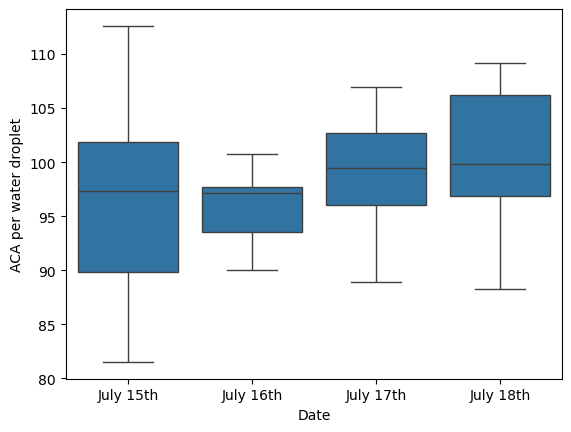

In [30]:
sns.boxplot(data=x, x='Date', y='ACA per water droplet')

3 cm burned soil 72.05 19.20
6 cm burned soil 42.32 19.26
Ash 52.62 9.72
Charred Layer 69.21 20.13
Repellent Layer 98.34 6.75
Unburned below 2in 30.98 5.54
Unburned top 2in 50.69 9.51


c:\Users\nmmas\anaconda3\Lib\site-packages\seaborn\axisgrid.py:854: UserWarning: The palette list has more values (12) than needed (7), which may not be intended.
  func(*plot_args, **plot_kwargs)
c:\Users\nmmas\anaconda3\Lib\site-packages\seaborn\axisgrid.py:854: UserWarning: The palette list has more values (12) than needed (7), which may not be intended.
  func(*plot_args, **plot_kwargs)
c:\Users\nmmas\anaconda3\Lib\site-packages\seaborn\axisgrid.py:854: UserWarning: The palette list has more values (12) than needed (7), which may not be intended.
  func(*plot_args, **plot_kwargs)
c:\Users\nmmas\anaconda3\Lib\site-packages\seaborn\axisgrid.py:854: UserWarning: The palette list has more values (12) than needed (7), which may not be intended.
  func(*plot_args, **plot_kwargs)
c:\Users\nmmas\anaconda3\Lib\site-packages\seaborn\axisgrid.py:854: UserWarning: The palette list has more values (12) than needed (7), which may not be intended.
  func(*plot_args, **plot_kwargs)


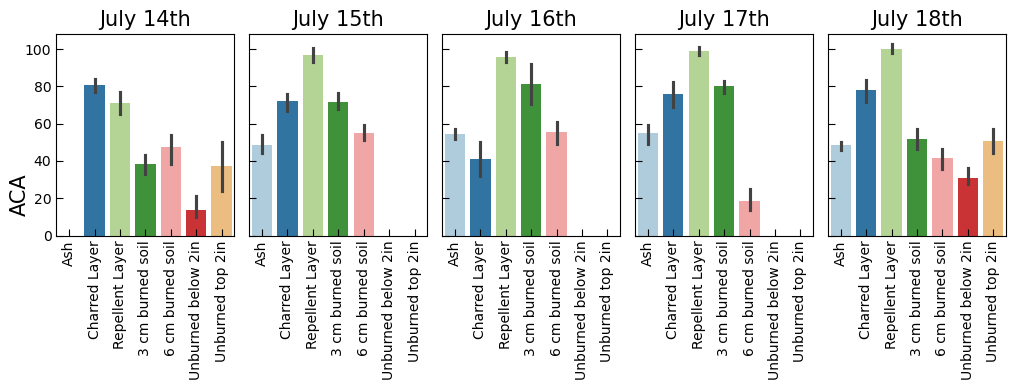

In [12]:
df = aca_df.copy()

mask = ~(df['Date'].str.contains('14'))

mean = df[mask].groupby(['Type'])['ACA per water droplet'].mean()
std = df[mask].groupby(['Type'])['ACA per water droplet'].std()

for my_type in mean.index:
    print(f"{my_type} {mean.loc[my_type]:.2f} {std.loc[my_type]:.2f}")


df = aca_temp_max_max_df.copy()

mask1 = (df['Type'].str.contains('Repellent Layer') 
         & df['Depth'].str.contains('Surface'))
mask2 = (df['Type'].str.contains('3 cm') 
         & df['Depth'].str.contains('3 cm'))
mask3 = (df['Type'].str.contains('6 cm') 
         & df['Depth'].str.contains('6 cm'))
mask4 = (df['Type'].str.contains('Charred') 
         & df['Depth'].str.contains('Surface'))
mask5 = (df['Type'].str.contains('Ash') 
         & df['Depth'].str.contains('Surface'))

mask = mask1 + mask2 + mask3 + mask4 + mask5

g = sns.FacetGrid(aca_df,height=4, aspect=.5, col='Date',
                                #   col_order=['July 18th'],
                  margin_titles=True, despine=False, sharex=True)#, hue='rep')
# g.map_dataframe(sns.regplot, x=x, y=y, scatter = False, color=c)#, ci=None)
g.map_dataframe(sns.barplot, x='Type', y='ACA per water droplet', hue='Type', 
                hue_order=['Ash','Charred Layer','Repellent Layer','3 cm burned soil','6 cm burned soil','Unburned below 2in', 'Unburned top 2in'],
                order = ['Ash','Charred Layer','Repellent Layer','3 cm burned soil','6 cm burned soil','Unburned below 2in', 'Unburned top 2in'],
                palette=sns.color_palette("Paired") #'rocket'
                )



g.set_axis_labels("", "")

# g.fig.text(0.4, -0.06, 'Date', ha='center', va='center', size=15)
g.fig.text(0.01, 0.5, 'ACA', ha='center', va='center', rotation='vertical', size=15)

g.set_titles(row_template="{row_name}", col_template="{col_name}", size=15)

g.tick_params(
    axis='both',
    which='major',
    length=5,
    direction='in'
)


g.figure.subplots_adjust(wspace=0, hspace=0)



for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(90)


g.add_legend()
plt.tight_layout()

savefig('aca_summary.jpg')

plt.show()


# Remote Sensing

## Calculating NBR

In [36]:
b8_dic = {}
b12_dic = {}

b8 = {}
b12 = {}

for my_type in order[:-2]:
    b8_dic[my_type] = {}
    b12_dic[my_type] = {}

    for date,sample_list in allsamples_dic.items():
        # if date != 'Jul14':
        try:
            df = sample_list[my_type][f'{my_type}_means']
            
            b8 = df.loc[785:899].mean()
            b12 = df.loc[2100:2280].mean()

            b8_dic[my_type][date] = b8.rename(date)
            b12_dic[my_type][date] = b12.rename(date)
        except:
            1



my_type = 'pink'
date = 'Jul15'

nbr_all = {} # Calculate NBR for all samples and mean
nbr_samples = {} # drop mean from above

for my_type in b8_dic.keys():

    nbr_all[my_type] = {}
    nbr_samples[my_type] = {}

    for date in b8_dic[my_type].keys():
        
        nbr = (b8_dic[my_type][date]-b12_dic[my_type][date])/(b8_dic[my_type][date]+b12_dic[my_type][date])
        nbr.drop('std', inplace=True)
        nbr_s = nbr.drop('mean')

        nbr_all[my_type][date] = nbr
        nbr_samples[my_type][date] = nbr_s

# Making means into a single df for comparison

nbr_df_dic = {}
nbr_samples_df_dic = {}

for my_type, sample_list in nbr_all.items():
    nbr_type_dic = {}

    for date, date_nbr in sample_list.items():
        nbr_type_dic[date] = date_nbr['mean']
    
    nbr_type_df = pd.DataFrame.from_dict(nbr_type_dic, orient='index')
    nbr_type_df = nbr_type_df.rename(columns={0:lineformats[my_type][1]})

    nbr_df_dic[my_type] = nbr_type_df

nbr_df = pd.concat(nbr_df_dic.values(), axis=1)



for my_type, sample_list in nbr_samples.items():
    nbr_type_dic = {}

    for date, date_nbr in sample_list.items():
        nbr_val_dic = [np.nan, np.nan, np.nan, np.nan, np.nan]

        i=0
        for val in date_nbr:
            nbr_val_dic[i] = val
            i+=1
        nbr_type_dic[date] = nbr_val_dic
    
    nbr_type_df = pd.DataFrame.from_dict(nbr_type_dic, orient='index')
    nbr_type_df = nbr_type_df.rename(columns={0:lineformats[my_type][1]})

    nbr_samples_df_dic[lineformats[my_type][1]] = nbr_type_dic


# Create multi index dict
reformed_dict = {}
for outerKey, innerDict in nbr_samples_df_dic.items():
    for innerKey, values in innerDict.items():
        reformed_dict[(outerKey,
                       innerKey)] = values

# Create df from multi index dict
multiIndex_df = pd.DataFrame(reformed_dict)

multiIndex_df = multiIndex_df.T

multiIndex_df.index = pd.MultiIndex.from_tuples(multiIndex_df.index, names=['Type', 'Date'])
multiIndex_df

# print(multiIndex_df)


# Reformat multi index df for correlation calculations
swapped_index = multiIndex_df.swaplevel(0,1,axis=0).sort_index()
swapped_index.loc['Jul15'].T

transposed = swapped_index.copy()

transposed_dic = {}

for day in transposed.index.get_level_values('Date'):
    transposed_dic[day] = transposed.loc[day].T

nbr_df_multisample = pd.concat(transposed_dic, axis=0)
nbr_df_multisample.index.names = ['Date', 'rep']
nbr_df_multisample.index = nbr_df_multisample.index.set_levels(pd.RangeIndex(1,6,1, name='rep'), level=1)


print(nbr_df_multisample)


# Make heat flux df to match with multi index NBR df

temp_int

dfs = [temp_int]*5
rep_df = pd.concat(dfs, ignore_index=True)

rep_level = np.repeat([1,2,3,4,5], len(temp_int))
index_level = np.tile(temp_int.index, 5)

rep_df.index = pd.MultiIndex.from_arrays(
    [rep_level, index_level],
    names=['SN','Date']
)

heatflux_samples = rep_df.swaplevel(0,1,axis=0).sort_index()


# print(heatflux_samples)






Type       3 cm deep burned soil  6 cm deep burned soil  Charred layer  \
Date  rep                                                                
Jul14 1                -0.277245              -0.245347      -0.418271   
      2                -0.269377                    NaN            NaN   
      3                      NaN                    NaN            NaN   
      4                      NaN                    NaN            NaN   
      5                      NaN                    NaN            NaN   
Jul15 1                -0.272082              -0.263346      -0.562679   
      2                -0.266703              -0.221838      -0.547662   
      3                -0.255616              -0.244488            NaN   
      4                      NaN                    NaN            NaN   
      5                      NaN                    NaN            NaN   
Jul16 1                -0.293066              -0.250793      -0.553604   
      2                -0.361304      

## Correlation of temp and NBR

In [10]:
temp_comp_df = temp_int.copy()
temp_comp_df['Date'] = ['July 15th', 'July 16th', 'July 17th', 'July 18th']

df1 = temp_comp_df.drop(columns=['Date']).rename_axis(['Depth'], axis=1).stack().reset_index()

df1 = df1.rename(columns={'level_0':'Date',0:'Heat Flux'})

day_dic = {
    'Jul14':'July 14th',
    'Jul15':'July 15th',
    'Jul16':'July 16th',
    'Jul17':'July 17th',
    'Jul18':'July 18th'
}


df2 = nbr_df_multisample.reset_index()
df2['Date'] = df2['Date'].map(day_dic)
df1['Date'] = df1['Date'].map(day_dic)
df2.rename(columns={'SN':'rep'}, inplace=True)

df2

df2_stacked = (df2.set_index(['Date','rep'])
                .rename_axis(['Type'], axis=1)
                .stack()
                .reset_index()
)

df2_stacked.rename(columns={0:'NBR'}, inplace=True)

df2_stacked



nbr_temp_sums_df = df1.merge(df2_stacked, on=['Date'])

nbr_temp_sums_df


# Make a df comparing NBR and the max of thermocouple data nbr_temp_max_df
nbr_temp_max_df = temp_max_df.merge(df2_stacked, on='Date')
nbr_temp_max_max_df = temp_max_max_df.merge(df2_stacked, on='Date')

nbr_temp_max_df


,Date,Max Temp,R,Depth,Thermocouple,rep,Type,NBR
0,July 15th,93.692,0,6 cm,iButton,1,3 cm deep burned soil,-0.272082
1,July 15th,93.692,0,6 cm,iButton,1,6 cm deep burned soil,-0.263346
2,July 15th,93.692,0,6 cm,iButton,1,Charred layer,-0.562679
3,July 15th,93.692,0,6 cm,iButton,1,Repellent layer,-0.318222
4,July 15th,93.692,0,6 cm,iButton,1,Ash,0.018673
...,...,...,...,...,...,...,...,...
1295,July 18th,66.600,15,3 cm,T12,5,3 cm deep burned soil,NaN
1296,July 18th,66.600,15,3 cm,T12,5,6 cm deep burned soil,NaN
1297,July 18th,66.600,15,3 cm,T12,5,Charred layer,NaN
1298,July 18th,66.600,15,3 cm,T12,5,Repellent layer,NaN


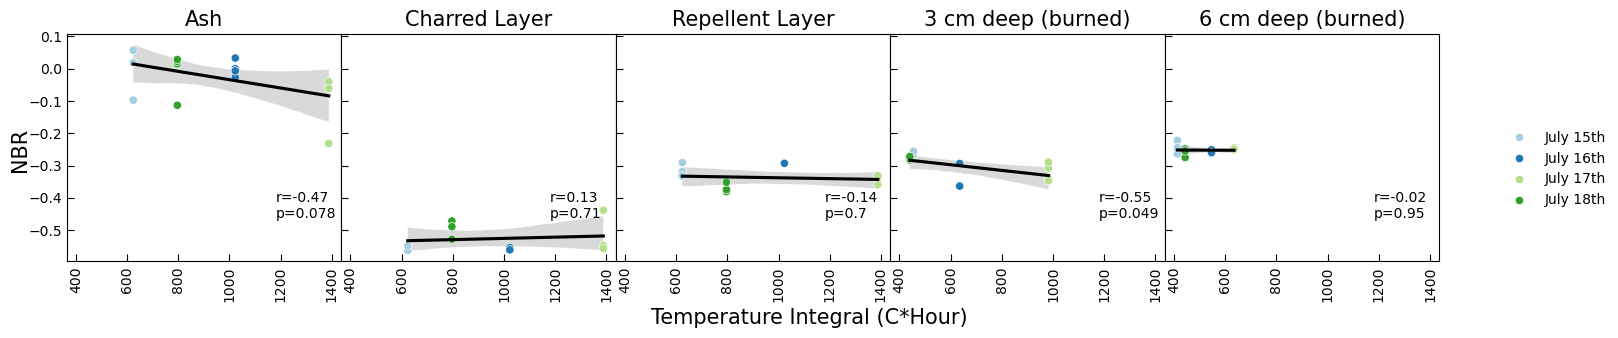

In [ ]:
df = nbr_temp_sums_df.copy()

mask1 = (df['Type'].str.contains('Repellent Layer') 
         & df['Depth'].str.contains('Surface'))
mask2 = (df['Type'].str.contains('3 cm') 
         & df['Depth'].str.contains('3 cm'))
mask3 = (df['Type'].str.contains('6 cm') 
         & df['Depth'].str.contains('6 cm'))
mask4 = (df['Type'].str.contains('Charred') 
         & df['Depth'].str.contains('Surface'))
mask5 = (df['Type'].str.contains('Ash') 
         & df['Depth'].str.contains('Surface'))


mask = mask1 + mask2 + mask3 + mask4 + mask5

# df.set_index(['Date','Type'], inplace=True)
# df = df[['ACA per water droplet','NBR']].groupby(level=[0,1]).mean()
# df=df.reset_index()

g = sns.FacetGrid(df[mask],col='Type', #row = 'Depth',
                  col_order=['Ash','Charred Layer','Repellent Layer','3 cm burned soil','6 cm burned soil'],
                  margin_titles=True, despine=False, sharex=True)#, hue='rep')
g.map_dataframe(sns.regplot, x='Heat Flux', y="NBR", scatter = False, color='k')#, ci=None)
g.map_dataframe(sns.scatterplot, x='Heat Flux', y="NBR", hue='Date', 
                palette=sns.color_palette("Paired", 4), #'rocket'
                hue_order = ['July 15th', 'July 16th', 'July 17th', 'July 18th'])

g.set_axis_labels("", "")


def annotate(data, **kws):
    r, p = stats.pearsonr(data['Heat Flux'], data['NBR'])
    ax = plt.gca()
    if p<0.01:
        ax.text(0.76, 0.19, 'r={:.2f}\np<0.01'.format(r, p),
            transform=ax.transAxes)
    else:
        ax.text(0.76, 0.19, 'r={:.2f}\np={:.2g}'.format(r, p),
            transform=ax.transAxes)
    
g.map_dataframe(annotate)




g.fig.text(0.5, -0.06, 'Temperature Integral (C*Hour)', ha='center', va='center', size=15)
g.fig.text(0.01, 0.5, 'NBR', ha='center', va='center', rotation='vertical', size=15)

g.set_titles(col_template="{col_name}",row_template='{row_name}', size=15)
g.tick_params(
    axis='both',
    which='major',
    length=5,
    direction='in'
)

g.figure.subplots_adjust(wspace=0, hspace=0)


g.add_legend()
for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(90)
plt.show()

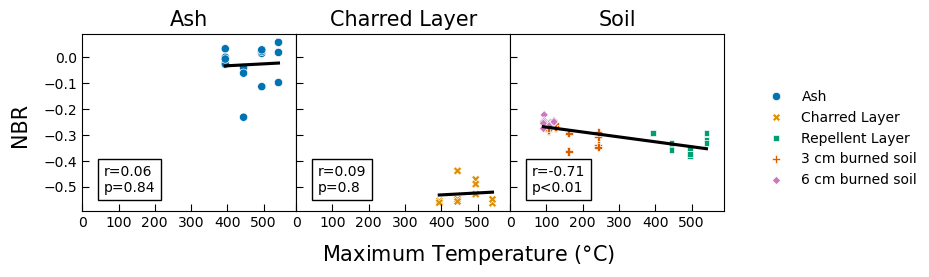

In [14]:
df = nbr_temp_max_max_df.copy()

mask1 = (df['Type'].str.contains('Repellent Layer') 
         & df['Depth'].str.contains('Surface'))
mask2 = (df['Type'].str.contains('3 cm') 
         & df['Depth'].str.contains('3 cm'))
mask3 = (df['Type'].str.contains('6 cm') 
         & df['Depth'].str.contains('6 cm'))
mask4 = (df['Type'].str.contains('Charred') 
         & df['Depth'].str.contains('Surface'))
mask5 = (df['Type'].str.contains('Ash') 
         & df['Depth'].str.contains('Surface'))


mask = mask1 + mask2 + mask3 + mask4 + mask5

dict1 = {
    'Repellent Layer':'Soil',
    '3 cm burned soil':'Soil',
    '6 cm burned soil':'Soil',
    'Charred Layer':'Charred Layer',
    'Ash':'Ash'
}

df = df[mask]
df['graph'] = df['Type'].map(dict1)

x='Max Temp'

g = sns.FacetGrid(df,col='graph', #row='Depth',
                #   col_order=['Soil','Charred Layer','Ash'],
                  col_order = ['Ash', 'Charred Layer', 'Soil'],
                #   col_order=['Ash','Charred Layer','Repellent Layer','3 cm burned soil','6 cm burned soil'],
                #   row_order=['Surface','3 cm','6 cm'],
                height=2.5, aspect=1,
                  margin_titles=True, despine=False, sharex=True)#, hue='rep')
g.map_dataframe(sns.regplot, x=x, y="NBR", scatter = False, color='k', ci=None)
g.map_dataframe(sns.scatterplot, x=x, y="NBR", hue='Type', style='Type',
                palette=sns.color_palette("colorblind", 5), #'rocket'
                hue_order = ['Ash','Charred Layer','Repellent Layer','3 cm burned soil','6 cm burned soil'],
                style_order = ['Ash','Charred Layer','Repellent Layer','3 cm burned soil','6 cm burned soil']
                # hue_order = ['July 15th', 'July 16th', 'July 17th', 'July 18th']
                # hue_order = [0,5,10,15]
                )

g.set_axis_labels("", "")


def annotate(data, **kws):
    r, p = stats.pearsonr(data[x], data['NBR'])
    ax = plt.gca()
    if p<0.01:
        ax.text(0.1, 0.11, 'r={:.2f}\np<0.01'.format(r, p),
            transform=ax.transAxes, bbox={'facecolor':'#fff'})
    else:
        ax.text(0.1, 0.11, 'r={:.2f}\np={:.2g}'.format(r, p),
            transform=ax.transAxes, bbox={'facecolor':'#fff'})
    
g.map_dataframe(annotate)



g.fig.text(0.5, -0.02, r'Maximum Temperature ($\degree$C)', ha='center', va='center', size=15)
g.fig.text(0.01, 0.5, 'NBR', ha='center', va='center', rotation='vertical', size=15)

g.set_titles(col_template="{col_name}",row_template='{row_name}', size=15)
# g.set_titles(col_template="",row_template='{row_name}', size=15)
g.tick_params(
    axis='both',
    which='major',
    length=5,
    direction='in'
)

g.figure.subplots_adjust(wspace=0, hspace=0)





g.set(xlim=(0,590), xticks=[0,100,200,300,400,500], yticks=np.arange(-0.5,0.1,0.1))



g.add_legend()
# for ax in g.axes.flat:
#     for label in ax.get_xticklabels():
#         label.set_rotation(90)

savefig('temp_nbr.jpg')

plt.show()

In [ ]:
mask_1 = df['']

mask1 = (df['Type'].str.contains('Repellent Layer') 
         & df['Depth'].str.contains('Surface'))
mask2 = (df['Type'].str.contains('3 cm') 
         & df['Depth'].str.contains('3 cm'))
mask3 = (df['Type'].str.contains('6 cm') 
         & df['Depth'].str.contains('6 cm'))
mask4 = (df['Type'].str.contains('Charred') 
         & df['Depth'].str.contains('Surface'))
mask5 = (df['Type'].str.contains('Ash') 
         & df['Depth'].str.contains('Surface'))

c:\Users\nmmas\anaconda3\Lib\site-packages\seaborn\axisgrid.py:854: UserWarning: The palette list has more values (12) than needed (5), which may not be intended.
  func(*plot_args, **plot_kwargs)
C:\Users\nmmas\AppData\Local\Temp\ipykernel_18164\539679396.py:38: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  subset_data = current_facet_data[mask_some]
C:\Users\nmmas\AppData\Local\Temp\ipykernel_18164\539679396.py:47: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  slope, intercept, r_value, p_value, std_err = stats.linregress(data[mask_some]['Heat Flux'], data[mask_some]['NBR'])
C:\Users\nmmas\AppData\Local\Temp\ipykernel_18164\539679396.py:47: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  slope, intercept, r_value, p_value, std_err = stats.linregress(data[mask_some]['Heat Flux'], data[mask_some]['NBR'])


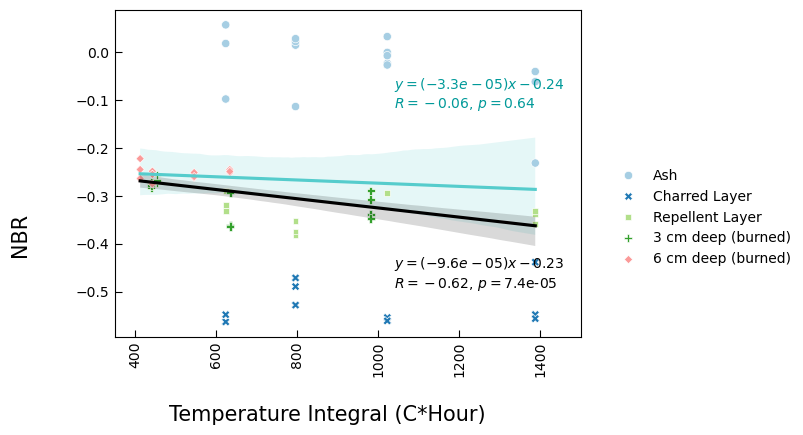

In [ ]:
df = nbr_temp_sums_df



mask1 = (df['Type'].str.contains('Repellent') 
         & df['Depth'].str.contains('Surface'))
mask2 = (df['Type'].str.contains('3 cm') 
         & df['Depth'].str.contains('3 cm'))
mask3 = (df['Type'].str.contains('6 cm') 
         & df['Depth'].str.contains('6 cm'))
mask4 = (df['Type'].str.contains('Charred') 
         & df['Depth'].str.contains('Surface'))
mask5 = (df['Type'].str.contains('Ash') 
         & df['Depth'].str.contains('Surface'))


mask_all = mask1 + mask2 + mask3 + mask4 + mask5
mask_some = mask1 + mask2 + mask3


g = sns.FacetGrid(df[mask_all], #row = 'Depth',col='Type', col_order=['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'],
                  margin_titles=True, despine=False, sharex=True,height=4, aspect=1.5)#, hue='rep')
g.map_dataframe(sns.regplot, x='Heat Flux', y="NBR", scatter = False, color='#5cc')#, ci=None)
g.map_dataframe(sns.scatterplot, x='Heat Flux', y="NBR", hue='Type',style='Type', 
                palette=sns.color_palette("Paired"), #'rocket'
                hue_order = ['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'],
                style_order = ['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'])




###

def plot_filtered_regression(x, y, **kwargs):
    # 'data' is passed via kwargs when using FacetGrid.map_dataframe
    # Filter the data within the function scope for the current facet's data subset
    current_facet_data = kwargs.pop('data')
    subset_data = current_facet_data[mask_some]
    sns.regplot(x=x, y=y, data=subset_data, scatter=False, ax=plt.gca(), **kwargs)

g.map_dataframe(plot_filtered_regression, x='Heat Flux', y="NBR", color='k')


# Annotate black reg line (no ash or charred)
def annotate(data, **kws):
    # r, p = stats.pearsonr(data[mask]['NBR'], data[mask]['ACA per water droplet'])
    slope, intercept, r_value, p_value, std_err = stats.linregress(data[mask_some]['Heat Flux'], data[mask_some]['NBR'])

    ax = plt.gca()
    # ax.text(0.3, 0.27, 'r={:.2f}\np={:.2g}'.format(r, p),
    #         transform=ax.transAxes)

    ax.text(0.6,0.15, f'$y=({slope:.2g})x{intercept:+.2f}$\n$R={r_value:.2f}$, $p=${p_value:.2g}',
            transform=ax.transAxes)
    
g.map_dataframe(annotate)



# Annotate blue reg line (all sample types)
def annotate(data, **kws):
    slope, intercept, r_value, p_value, std_err = stats.linregress(data['Heat Flux'], data['NBR'])

    ax = plt.gca()

    ax.text(0.6,0.7, f'$y=({slope:.2g})x{intercept:+.2f}$\n$R={r_value:.2f}$, $p=${p_value:.2g}',
            transform=ax.transAxes, color='#099')
    
g.map_dataframe(annotate)


g.set_axis_labels("", "")

###


g.fig.text(0.4, -0.05, 'Temperature Integral (C*Hour)', ha='center', va='center', size=15)
g.fig.text(0.01, 0.4, 'NBR', ha='center', va='center', rotation='vertical', size=15)

g.tick_params(
    axis='both',
    which='major',
    length=5,
    direction='in'
)


g.set(xlim=(350,1500))

g.figure.subplots_adjust(wspace=0, hspace=0)

g.add_legend()
for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(90)

plt.show()





c:\Users\nmmas\anaconda3\Lib\site-packages\seaborn\axisgrid.py:854: UserWarning: The palette list has more values (12) than needed (5), which may not be intended.
  func(*plot_args, **plot_kwargs)
C:\Users\nmmas\AppData\Local\Temp\ipykernel_13628\4178896111.py:38: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  subset_data = current_facet_data[mask_some]
C:\Users\nmmas\AppData\Local\Temp\ipykernel_13628\4178896111.py:47: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  slope, intercept, r_value, p_value, std_err = stats.linregress(data[mask_some]['Max Temp'], data[mask_some]['NBR'])
C:\Users\nmmas\AppData\Local\Temp\ipykernel_13628\4178896111.py:47: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  slope, intercept, r_value, p_value, std_err = stats.linregress(data[mask_some]['Max Temp'], data[mask_some]['NBR'])


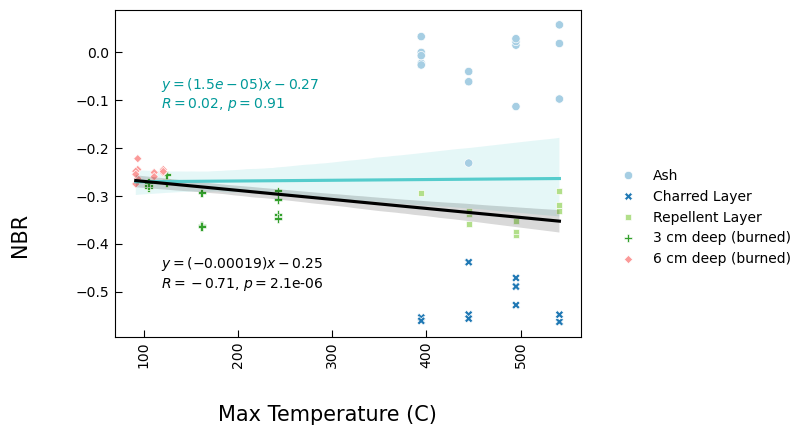

In [ ]:
df = nbr_temp_max_max_df



mask1 = (df['Type'].str.contains('Repellent') 
         & df['Depth'].str.contains('Surface'))
mask2 = (df['Type'].str.contains('3 cm') 
         & df['Depth'].str.contains('3 cm'))
mask3 = (df['Type'].str.contains('6 cm') 
         & df['Depth'].str.contains('6 cm'))
mask4 = (df['Type'].str.contains('Charred') 
         & df['Depth'].str.contains('Surface'))
mask5 = (df['Type'].str.contains('Ash') 
         & df['Depth'].str.contains('Surface'))


mask_all = mask1 + mask2 + mask3 + mask4 + mask5
mask_some = mask1 + mask2 + mask3


g = sns.FacetGrid(df[mask_all], #row = 'Depth',col='Type', col_order=['Ash','Charred layer','Repellent layer','3 cm burned soil','6 cm burned soil'],
                  margin_titles=True, despine=False, sharex=True,height=4, aspect=1.5)#, hue='rep')
g.map_dataframe(sns.regplot, x='Max Temp', y="NBR", scatter = False, color='#5cc')#, ci=None)
g.map_dataframe(sns.scatterplot, x='Max Temp', y="NBR", hue='Type',style='Type', 
                palette=sns.color_palette("colorblind"), #'rocket'
                hue_order = ['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'],
                style_order = ['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'])




###

def plot_filtered_regression(x, y, **kwargs):
    # 'data' is passed via kwargs when using FacetGrid.map_dataframe
    # Filter the data within the function scope for the current facet's data subset
    current_facet_data = kwargs.pop('data')
    subset_data = current_facet_data[mask_some]
    sns.regplot(x=x, y=y, data=subset_data, scatter=False, ax=plt.gca(), **kwargs)

g.map_dataframe(plot_filtered_regression, x='Max Temp', y="NBR", color='k')


# Annotate black reg line (no ash or charred)
def annotate(data, **kws):
    # r, p = stats.pearsonr(data[mask]['NBR'], data[mask]['ACA per water droplet'])
    slope, intercept, r_value, p_value, std_err = stats.linregress(data[mask_some]['Max Temp'], data[mask_some]['NBR'])

    ax = plt.gca()
    # ax.text(0.3, 0.27, 'r={:.2f}\np={:.2g}'.format(r, p),
    #         transform=ax.transAxes)

    ax.text(0.1,0.15, f'$y=({slope:.2g})x{intercept:+.2f}$\n$R={r_value:.2f}$, $p=${p_value:.2g}',
            transform=ax.transAxes)
    
g.map_dataframe(annotate)



# Annotate blue reg line (all sample types)
def annotate(data, **kws):
    slope, intercept, r_value, p_value, std_err = stats.linregress(data['Max Temp'], data['NBR'])

    ax = plt.gca()

    ax.text(0.1,0.7, f'$y=({slope:.2g})x{intercept:+.2f}$\n$R={r_value:.2f}$, $p=${p_value:.2g}',
            transform=ax.transAxes, color='#099')
    
g.map_dataframe(annotate)


g.set_axis_labels("", "")

###


g.fig.text(0.4, -0.05, 'Max Temperature (C)', ha='center', va='center', size=15)
g.fig.text(0.01, 0.4, 'NBR', ha='center', va='center', rotation='vertical', size=15)

g.tick_params(
    axis='both',
    which='major',
    length=5,
    direction='in'
)


# g.set(xlim=(350,1500))

g.figure.subplots_adjust(wspace=0, hspace=0)

g.add_legend()
for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(90)

plt.show()





## Correlation of temp and Reflectance @ wavelengths

In [ ]:
day_dic = {
    'Jul14':'July 14th',
    'Jul15':'July 15th',
    'Jul16':'July 16th',
    'Jul17':'July 17th',
    'Jul18':'July 18th'
}

# Create Reflectance Sample df

ref_sample_dic = {}

for w in wavelengths:
    ref_dict = {}

    for my_type, sample_list in sorted_dic.items():
        

        df = sample_list[f'{my_type}_samplemeans'].loc[w].drop(['mean','std']).reset_index()
        df['Date'] = df['index'].str.split('-', expand=True)[0]
        df = df.drop(columns=['index'])

        df['SN'] = df.groupby('Date').cumcount()
        df.set_index(['Date','SN'], inplace=True)

        ref_dict[lineformats[my_type][1]] = df.rename(columns={w:lineformats[my_type][1]})


    ref_sample_df = pd.concat(ref_dict.values(), axis=1, join='outer').drop(columns=['Below 5 cm unburned','Top 5 cm unburned'], errors='ignore')
    ref_sample_dic[w] = ref_sample_df


r={}

for lamba,n in ref_sample_dic.items():
    m = n.reset_index()
    m['Wavelength'] = np.repeat(lamba, 19)
    r[lamba] = m

ref_sample_df = pd.concat(r.values())

ref_sample_df = (ref_sample_df.set_index(['Date','SN','Wavelength']).stack()
                 .rename('Reflectance').reset_index()\
                 .rename(columns={'level_3':'Type','SN':'rep'})
                )

ref_sample_df['rep'] = ref_sample_df['rep']+1
ref_sample_df = ref_sample_df.sort_values(['Date','Type','rep','Wavelength']).reset_index(drop=True)
ref_sample_df['Date'] = ref_sample_df['Date'].map(day_dic)
ref_sample_df


# Create a max temp v reflectance comparison df

ref_temp_max_max_df = ref_sample_df.merge(temp_max_max_df, on='Date')


temp_comp_df = temp_int.copy()
temp_comp_df['Date'] = ['July 15th', 'July 16th', 'July 17th', 'July 18th']

df1 = temp_comp_df.drop(columns=['Date']).rename_axis(['Depth'], axis=1).stack().reset_index()

df1 = df1.rename(columns={'level_0':'Date',0:'Heat Flux'})

df1['Date'] = df1['Date'].map(day_dic)


ref_temp_sums_df = ref_sample_df.merge(df1, on='Date')


ref_temp_sums_df



,Date,rep,Wavelength,Type,Reflectance,Depth,Heat Flux
0,July 15th,1,500,3 cm deep (burned),0.091360,Surface,624.195417
1,July 15th,1,500,3 cm deep (burned),0.091360,3 cm,454.717583
2,July 15th,1,500,3 cm deep (burned),0.091360,6 cm,413.058000
3,July 15th,1,700,3 cm deep (burned),0.179608,Surface,624.195417
4,July 15th,1,700,3 cm deep (burned),0.179608,3 cm,454.717583
...,...,...,...,...,...,...,...
715,July 18th,3,1000,Repellent Layer,0.302178,3 cm,440.475278
716,July 18th,3,1000,Repellent Layer,0.302178,6 cm,443.325000
717,July 18th,3,2200,Repellent Layer,0.463383,Surface,796.525556
718,July 18th,3,2200,Repellent Layer,0.463383,3 cm,440.475278


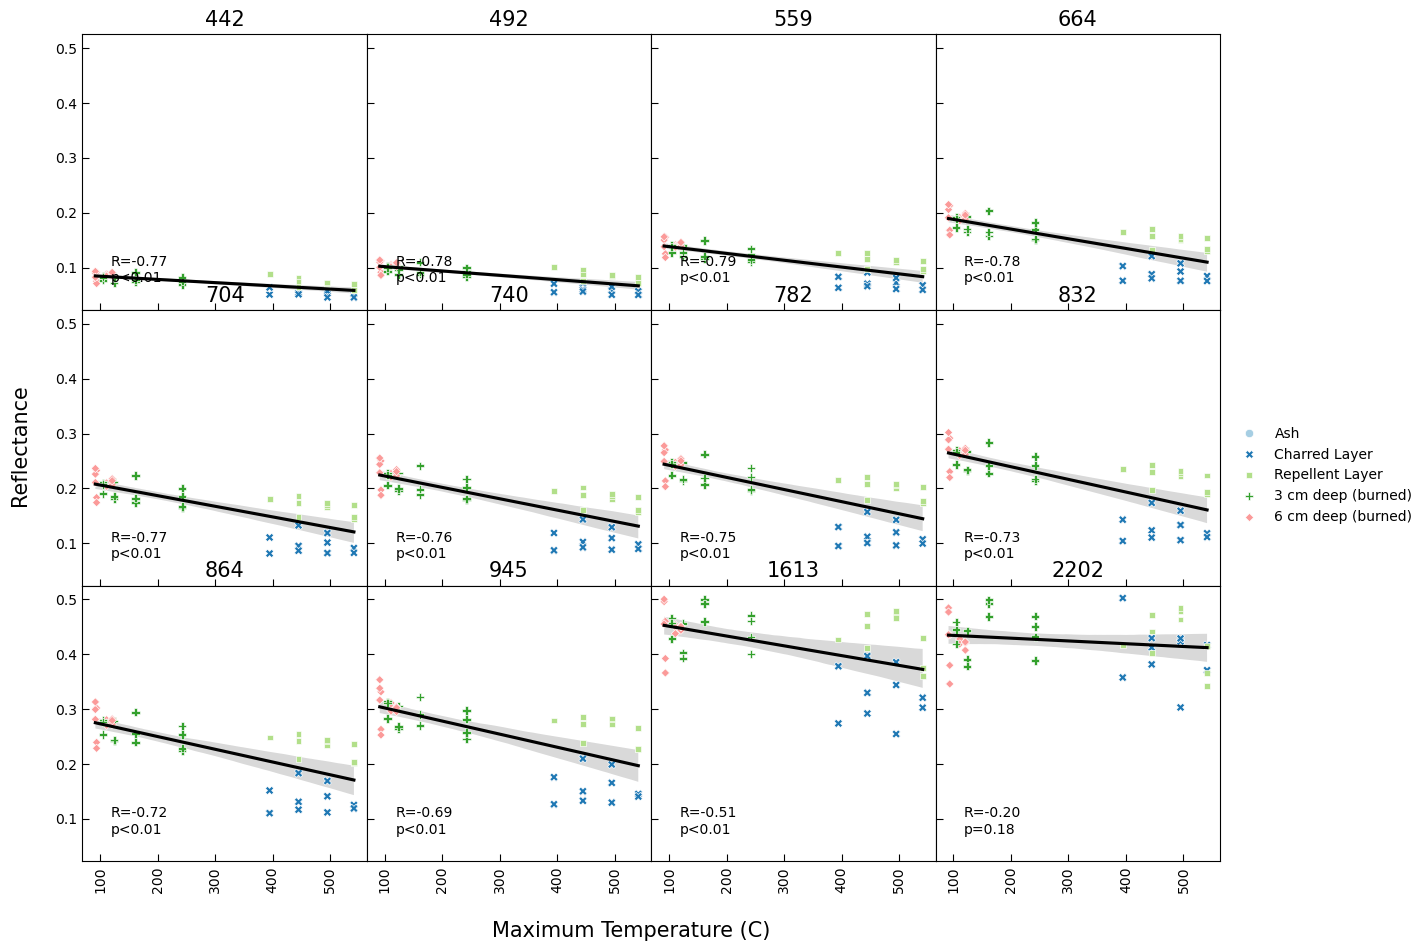

In [ ]:
# mask = ~(aca_temp_max_max_df['Type'].str.contains('Unburned'))
df = ref_temp_max_max_df

mask1 = (df['Type'].str.contains('Repellent') 
         & df['Depth'].str.contains('Surface'))
mask2 = (df['Type'].str.contains('3 cm') 
         & df['Depth'].str.contains('3 cm'))
mask3 = (df['Type'].str.contains('6 cm') 
         & df['Depth'].str.contains('6 cm'))
mask4 = (df['Type'].str.contains('Charred') 
         & df['Depth'].str.contains('Surface'))
mask5 = (df['Type'].str.contains('Ash') 
         & df['Depth'].str.contains('Surface'))


mask = mask1 + mask2 + mask3 + mask4 #+ mask5


x='Max Temp'
y='Reflectance'

import warnings
warnings.filterwarnings('ignore')  # Suppress all warnings

g = sns.FacetGrid(df[mask], col='Wavelength',sharex=True,sharey='row', col_wrap=4,
                  #col_order=['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'],
                  col_order=wavelengths,
                  margin_titles=True, despine=False)#, hue='rep')
g.map_dataframe(sns.regplot, x=x, y=y, scatter = False, color='k')#, ci=False)
g.map_dataframe(sns.scatterplot, x=x, y=y, hue='Type',style='Type', palette=sns.color_palette("Paired"),
                hue_order = ['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'],
                style_order = ['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'])

g.set_axis_labels("", "")

g.fig.text(0.43, -0.04, 'Maximum Temperature (C)', ha='center', va='center', size=15)
g.fig.text(-0.01, 0.5, 'Reflectance', ha='center', va='center', rotation='vertical', size=15)


g.set_titles(row_template="{row_name}", col_template="{col_name}", size=15)
g.tick_params(
    axis='both',
    which='major',
    length=5,
    direction='in'
)

def annotate(data, **kws):
    r, p = stats.pearsonr(data[x], data[y])

    if (p<0.01):
        
        ax = plt.gca()
        ax.text(.1, .1, 'R={:.2f}\np<0.01'.format(r, p),
                transform=ax.transAxes)
    else:
        ax = plt.gca()
        ax.text(.1, .1, 'R={:.2f}\np={:.2f}'.format(r, p),
                transform=ax.transAxes)
    
g.map_dataframe(annotate)


g.figure.subplots_adjust(wspace=0, hspace=0)

g.add_legend()
for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(90)
plt.show()

# ACA vs NBR

In [47]:
df1 = aca_df.copy()
df1.index.set_names('n', inplace=True)

day_dic = {
    'Jul14':'July 14th',
    'Jul15':'July 15th',
    'Jul16':'July 16th',
    'Jul17':'July 17th',
    'Jul18':'July 18th'
}




df2 = nbr_df_multisample.reset_index()
df2['Date'] = df2['Date'].map(day_dic)
df2.rename(columns={'SN':'rep'}, inplace=True)

df2

df2_stacked = (df2.set_index(['Date','rep'])
                .rename_axis(['Type'], axis=1)
                .stack()
                .reset_index()
)

df2_stacked.rename(columns={0:'NBR'}, inplace=True)

aca_nbr_fg = df1.merge(df2_stacked, on=['Date','rep','Type'])

aca_nbr_fg



,Sample type,ACA per water droplet,Date,Sample,Type,rep,NBR
0,July 14th - repellent layer rep 1 (half of the...,72.34,July 14th,repellent layer rep 1 (half of the slide),Repellent layer,1,-0.245997
1,July 14th - repellent layer rep 1 (half of the...,68.28,July 14th,repellent layer rep 1 (half of the slide),Repellent layer,1,-0.245997
2,July 14th - repellent layer rep 1 (half of the...,79.34,July 14th,repellent layer rep 1 (half of the slide),Repellent layer,1,-0.245997
3,July 14th - repellent layer rep 1 (half of the...,77.25,July 14th,repellent layer rep 1 (half of the slide),Repellent layer,1,-0.245997
4,July 14th - repellent layer rep 3,67.91,July 14th,repellent layer rep 3,Repellent layer,3,-0.258116
...,...,...,...,...,...,...,...
378,July 18th - repellent layer rep 2,106.22,July 18th,repellent layer rep 2,Repellent layer,2,-0.373936
379,July 18th - repellent layer rep 2,106.98,July 18th,repellent layer rep 2,Repellent layer,2,-0.373936
380,July 18th - repellent layer rep 2,106.20,July 18th,repellent layer rep 2,Repellent layer,2,-0.373936
381,July 18th - repellent layer rep 2,106.17,July 18th,repellent layer rep 2,Repellent layer,2,-0.373936


In [55]:
mask1 = ~(aca_nbr_fg['Type'].str.contains('Ash'))
mask2 = ~(aca_nbr_fg['NBR'] < -0.2)

mask = ~(mask1+mask2)

aca_nbr_fg[mask]

,Sample type,ACA per water droplet,Date,Sample,Type,rep,NBR
195,July 17th - ash rep 1,49.98,July 17th,ash rep 1,Ash,1,-0.231007
196,July 17th - ash rep 1,62.03,July 17th,ash rep 1,Ash,1,-0.231007
197,July 17th - ash rep 1,58.29,July 17th,ash rep 1,Ash,1,-0.231007
198,July 17th - ash rep 1,55.93,July 17th,ash rep 1,Ash,1,-0.231007
199,July 17th - ash rep 1,59.68,July 17th,ash rep 1,Ash,1,-0.231007
200,July 17th - ash rep 1,43.27,July 17th,ash rep 1,Ash,1,-0.231007
201,July 17th - ash rep 1,58.93,July 17th,ash rep 1,Ash,1,-0.231007


<Axes: xlabel='Wavelength'>

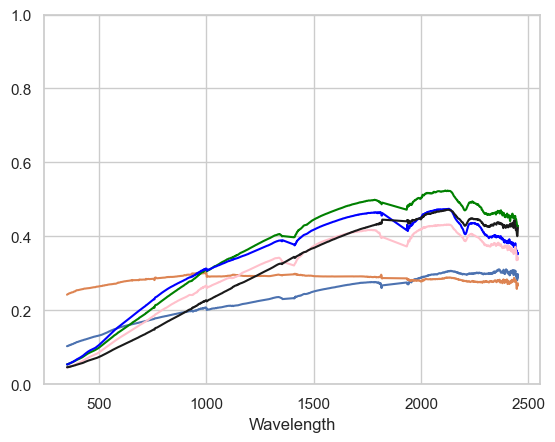

In [66]:
sorted_dic_dropped['white']['Jul17-white-1.txt']['mean'].plot(ylim=(0,1))
sorted_dic_dropped['white']['Jul18-white-1.txt']['mean'].plot(ylim=(0,1))
sorted_dic_dropped['green']['Jul17-green-1.txt']['mean'].plot(ylim=(0,1), color='green')
sorted_dic_dropped['blue']['Jul17-blue-1.txt']['mean'].plot(ylim=(0,1), color='blue')
sorted_dic_dropped['pink']['Jul17-pink-1.txt']['mean'].plot(color='pink')
sorted_dic_dropped['grey']['Jul17-grey-1.txt']['mean'].plot(color='k')

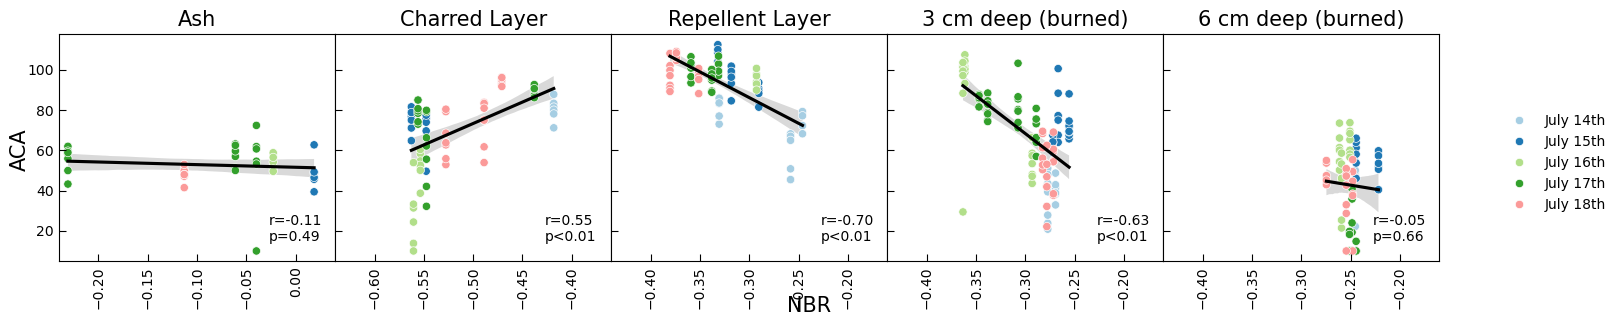

In [ ]:
df = aca_nbr_fg.copy()

# df.set_index(['Date','Type'], inplace=True)
# df = df[['ACA per water droplet','NBR']].groupby(level=[0,1]).mean()
# df=df.reset_index()

g = sns.FacetGrid(df, col='Type', col_order=['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'],
                  margin_titles=True, despine=False, sharex=False)#, hue='rep')
g.map_dataframe(sns.regplot, x='NBR', y=y, scatter = False, color='k')#, ci=None)
g.map_dataframe(sns.scatterplot, x='NBR', y="ACA per water droplet", hue='Date', 
                palette=sns.color_palette("Paired", 5), #'rocket'
                hue_order = ['July 14th', 'July 15th', 'July 16th', 'July 17th', 'July 18th'])

g.set_axis_labels("", "")


# Manually set x limits and labels



def set_ticks(ax, center, dx):

    ax.set_xlim(center-dx,center+dx)
    x_labels = ax.get_xticklabels()

    x_labels[0].set_visible(False)
    x_labels[-1].set_visible(False)
        

    major_ticks_x = ax.xaxis.get_major_ticks()
    if major_ticks_x:
        major_ticks_x[0].tick1On = False
        major_ticks_x[0].tick2On = False
        major_ticks_x[-1].tick1On = False
        major_ticks_x[-1].tick2On = False

dx = 0.14

center = -0.1
set_ticks(g.axes.flat[0], center = center, dx = dx)
center = -0.5
set_ticks(g.axes.flat[1], center = center, dx = dx)
center = -0.3
set_ticks(g.axes.flat[2], center = center, dx = dx)
center = -0.3
set_ticks(g.axes.flat[3], center = center, dx = dx)
center = -0.3
set_ticks(g.axes.flat[4], center = center, dx = dx)



def annotate(data, **kws):
    r, p = stats.pearsonr(data['NBR'], data['ACA per water droplet'])
    ax = plt.gca()
    if p<0.01:
        ax.text(0.76, 0.09, 'r={:.2f}\np<0.01'.format(r, p),
            transform=ax.transAxes)
    else:
        ax.text(0.76, 0.09, 'r={:.2f}\np={:.2g}'.format(r, p),
            transform=ax.transAxes)
    
g.map_dataframe(annotate)




g.fig.text(0.5, -0.02, 'NBR', ha='center', va='center', size=15)
g.fig.text(0.01, 0.5, 'ACA', ha='center', va='center', rotation='vertical', size=15)

g.set_titles(col_template="{col_name}", size=15)
g.tick_params(
    axis='both',
    which='major',
    length=5,
    direction='in'
)

g.figure.subplots_adjust(wspace=0, hspace=0)


g.add_legend()
for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(90)
plt.show()

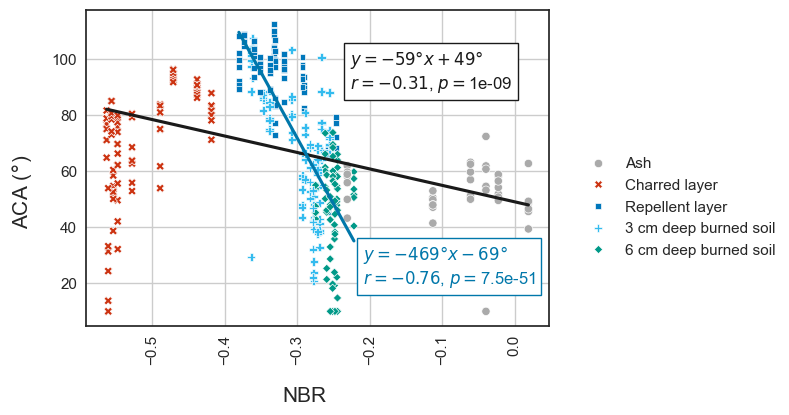

In [80]:
df = aca_nbr_fg.copy()


mask1 = (df['Type'].str.contains('Repellent layer'))
mask2 = (df['Type'].str.contains('3 cm'))
mask3 = (df['Type'].str.contains('6 cm'))


mask = mask1 + mask2 + mask3

c = '#55cccc'
c = "#EE7733"
c = "#0077aa"




g = sns.FacetGrid(df,height=4, aspect=1.5,
                  margin_titles=True, despine=False, sharex=False)#, hue='rep')
g.map_dataframe(sns.regplot, x='NBR', y="ACA per water droplet", scatter = False, color='k', ci=None)
g.map_dataframe(sns.scatterplot, x='NBR', y="ACA per water droplet", hue='Type',style='Type', 
                palette=color_cb, #'rocket'
                hue_order = ['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'],
                style_order = ['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil']
                )




# Add a black reg line for best fit (no ash or charred)
def plot_filtered_regression(x, y, **kwargs):
    # 'data' is passed via kwargs when using FacetGrid.map_dataframe
    # Filter the data within the function scope for the current facet's data subset
    current_facet_data = kwargs.pop('data')
    subset_data = current_facet_data[mask]
    sns.regplot(x=x, y=y, data=subset_data, scatter=False, ax=plt.gca(), **kwargs)

g.map_dataframe(plot_filtered_regression, x='NBR', y="ACA per water droplet", color=c, line_kws={'linestyle':'-'}, ci=None)


# Annotate blue reg line (no ash or charred)
def annotate(data, **kws):
    # r, p = stats.pearsonr(data[mask]['NBR'], data[mask]['ACA per water droplet'])
    slope, intercept, r_value, p_value, std_err = stats.linregress(data[mask]['NBR'], data[mask]['ACA per water droplet'])

    ax = plt.gca()
    # ax.text(0.3, 0.27, 'r={:.2f}\np={:.2g}'.format(r, p),
    #         transform=ax.transAxes)

    ax.text(0.597,0.135, f'$y={slope:.0f}\degree x{intercept:+.0f}\degree$\n$r = {r_value:.2f}$, $p = ${p_value:.2g}',
            transform=ax.transAxes,
            bbox={'facecolor':"#fff", 'edgecolor':c},
            color=c
            )
    
g.map_dataframe(annotate)



# Annotate black reg line (all sample types)
def annotate(data, **kws):
    slope, intercept, r_value, p_value, std_err = stats.linregress(data['NBR'], data['ACA per water droplet'])

    ax = plt.gca()

    ax.text(0.57,0.75, f'$y={slope:.0f}\degree x{intercept:+.0f}\degree$\n$r = {r_value:.2f}$, $p = ${p_value:.2g}',
            transform=ax.transAxes, color='k',
            bbox={'facecolor':'#fff', 'edgecolor':'k'})
    
g.map_dataframe(annotate)








g.set_axis_labels("", "")

g.fig.text(0.4, -0.01, 'NBR', ha='center', va='center', size=15)
g.fig.text(0.05, 0.5, 'ACA ($\degree$)', ha='center', va='center', rotation='vertical', size=15)

g.set_titles(col_template="{col_name}", size=15)
g.tick_params(
    axis='both',
    which='major',
    length=5,
    direction='inout'
)


g.figure.subplots_adjust(wspace=0, hspace=0)



for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(90)


g.add_legend()
plt.grid()
savefig('NBR_ACA.jpg')
plt.show()


In [ ]:
aca_corr = (aca_nbr_fg.reset_index().pivot(index=['Date', 'rep','index'], 
        columns ='Type', 
        values='ACA per water droplet')
        .reindex(['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'],axis=1))

aca_corr.set_index

nbr_corr = (aca_nbr_fg.reset_index().pivot(index=['Date', 'rep','index'], 
        columns ='Type', 
        values='NBR')
        .reindex(['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'],axis=1))

# nbr_corr.reset_index(inplace=True)

nbr_corr = (nbr_corr.rename_axis(['Type'], axis=1)
                     .stack().reset_index()
                     .set_index('index').sort_index()
                     .reset_index()
                     .set_index(['Date','rep','index']))
nbr_corr.rename(columns={0:'NBR'}, inplace=True)
nbr_corr.drop(columns=['Type'], inplace=True)
nbr_corr


NBR
Date      rep index          
July 14th 1   0     -0.245997
              1     -0.245997
              2     -0.245997
              3     -0.245997
          3   4     -0.258116
...                       ...
July 18th 2   378   -0.373936
              379   -0.373936
              380   -0.373936
              381   -0.373936
              382   -0.373936

[383 rows x 1 columns]

# ACA vs Temperature

In [38]:


# Format temperature integral ('heat flux') df
heatflux_samples_day = heatflux_samples.copy()

day_dic = {
    'Jul15':'July 15th',
    'Jul16':'July 16th',
    'Jul17':'July 17th',
    'Jul18':'July 18th'
}

heatflux_samples_day = heatflux_samples_day.reset_index()
heatflux_samples_day['Date'] = heatflux_samples_day['Date'].map(day_dic)
heatflux_samples_day.rename(columns={'SN':'rep'}, inplace=True)

heatflux_samples_day.set_index(['Date','rep'], inplace=True)

# Format ACA sample means df
aca_corr_means_df = aca_mean_by_group.copy()
aca_corr_means_df = (aca_corr_means_df.pivot(index=['Date', 'rep'], 
        columns ='Type', 
        values='ACA per water droplet')
        .drop(columns=['Unburned below 2in', 'Unburned top 2in'])
        .reindex(['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'],axis=1))



# Format ACA vs HF FacetGrid df
temp_comp_df = temp_int.copy()
temp_comp_df['Date'] = ['July 15th', 'July 16th', 'July 17th', 'July 18th']

aca_temp_sums_df = aca_df.copy()                # To compare against all ACA measurements
# aca_temp_sums_df = aca_mean_by_group.copy()   # To compare against average ACA per sample

aca_temp_sums_df = pd.merge(aca_temp_sums_df, temp_comp_df, on='Date')
aca_temp_sums_df = (aca_temp_sums_df.set_index(['ACA per water droplet',
                     'Date', 'Sample','Sample type',
                     'Type', 'rep'])
                     .rename_axis(['Depth'], axis=1)
                     .stack()
                     .reset_index())
aca_temp_sums_df.rename(columns={0:'Heat Flux'}, inplace=True)

aca_temp_sums_df


# ACA and Temp Max comparison df
aca_temp_max_df = pd.merge(aca_df, temp_max_df, on='Date')

aca_temp_max_max_df = pd.merge(aca_df, temp_max_max_df, on='Date')


temp_counts = temp_counts_df.groupby(['Date','Depth'])[['Minutes Above 175C','Minutes Above 200C',
                                                        'Minutes Above 280C','Minutes Above 400C',
                                                        'Minutes 175-200C']].max().reset_index()
aca_temp_count_df = pd.merge(aca_df, temp_counts, on='Date')

aca_temp_count_df


,Sample type,ACA per water droplet,Date,Sample,Type,rep,Depth,Minutes Above 175C,Minutes Above 200C,Minutes Above 280C,Minutes Above 400C,Minutes 175-200C
0,July 15th - repellent layer rep 1,101.75,July 15th,repellent layer rep 1,Repellent layer,1,3 cm,0.0,0.0,0.0,0.0,0.0
1,July 15th - repellent layer rep 1,101.75,July 15th,repellent layer rep 1,Repellent layer,1,Surface,64.0,55.0,39.0,29.0,9.0
2,July 15th - repellent layer rep 1,96.16,July 15th,repellent layer rep 1,Repellent layer,1,3 cm,0.0,0.0,0.0,0.0,0.0
3,July 15th - repellent layer rep 1,96.16,July 15th,repellent layer rep 1,Repellent layer,1,Surface,64.0,55.0,39.0,29.0,9.0
4,July 15th - repellent layer rep 1,98.23,July 15th,repellent layer rep 1,Repellent layer,1,3 cm,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
695,July 18th - repellent layer rep 2,106.20,July 18th,repellent layer rep 2,Repellent layer,2,Surface,132.0,122.0,106.0,31.0,11.0
696,July 18th - repellent layer rep 2,106.17,July 18th,repellent layer rep 2,Repellent layer,2,3 cm,0.0,0.0,0.0,0.0,0.0
697,July 18th - repellent layer rep 2,106.17,July 18th,repellent layer rep 2,Repellent layer,2,Surface,132.0,122.0,106.0,31.0,11.0
698,July 18th - repellent layer rep 2,108.48,July 18th,repellent layer rep 2,Repellent layer,2,3 cm,0.0,0.0,0.0,0.0,0.0


In [39]:
aca_temp_max_max_df

,Sample type,ACA per water droplet,Date,Sample,Type,rep,Depth,Max Temp
0,July 15th - repellent layer rep 1,101.75,July 15th,repellent layer rep 1,Repellent layer,1,3 cm,124.180000
1,July 15th - repellent layer rep 1,101.75,July 15th,repellent layer rep 1,Repellent layer,1,6 cm,93.692000
2,July 15th - repellent layer rep 1,101.75,July 15th,repellent layer rep 1,Repellent layer,1,Surface,541.050000
3,July 15th - repellent layer rep 1,96.16,July 15th,repellent layer rep 1,Repellent layer,1,3 cm,124.180000
4,July 15th - repellent layer rep 1,96.16,July 15th,repellent layer rep 1,Repellent layer,1,6 cm,93.692000
...,...,...,...,...,...,...,...,...
1045,July 18th - repellent layer rep 2,106.17,July 18th,repellent layer rep 2,Repellent layer,2,6 cm,91.572000
1046,July 18th - repellent layer rep 2,106.17,July 18th,repellent layer rep 2,Repellent layer,2,Surface,494.933333
1047,July 18th - repellent layer rep 2,108.48,July 18th,repellent layer rep 2,Repellent layer,2,3 cm,104.983333
1048,July 18th - repellent layer rep 2,108.48,July 18th,repellent layer rep 2,Repellent layer,2,6 cm,91.572000


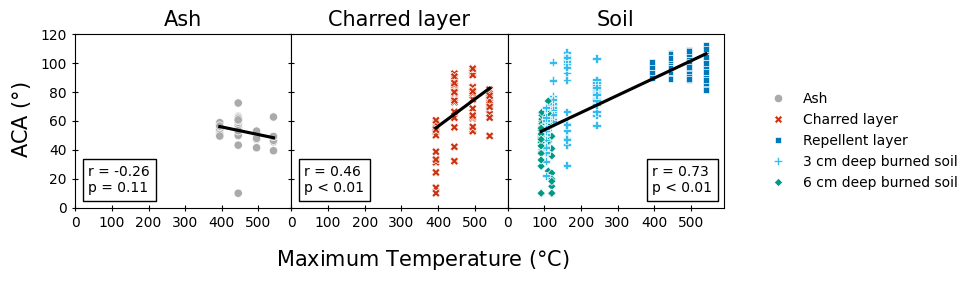

In [40]:
matplotlib.rc_file_defaults()

# mask = ~(aca_temp_max_max_df['Type'].str.contains('Unburned'))
df = aca_temp_max_max_df

mask1 = (df['Type'].str.contains('Repellent') 
         & df['Depth'].str.contains('Surface'))
mask2 = (df['Type'].str.contains('3 cm') 
         & df['Depth'].str.contains('3 cm'))
mask3 = (df['Type'].str.contains('6 cm') 
         & df['Depth'].str.contains('6 cm'))
mask4 = (df['Type'].str.contains('Charred') 
         & df['Depth'].str.contains('Surface'))
mask5 = (df['Type'].str.contains('Ash') 
         & df['Depth'].str.contains('Surface'))


mask = mask1 + mask2 + mask3 + mask4 + mask5



dict1 = {
    'Repellent layer':'Soil',
    '3 cm deep burned soil':'Soil',
    '6 cm deep burned soil':'Soil',
    'Charred layer':'Charred layer',
    'Ash':'Ash'
}

df = df[mask]
df['graph'] = df['Type'].map(dict1)

x='Max Temp'
y = 'ACA per water droplet'


import warnings
warnings.filterwarnings('ignore')  # Suppress all warnings

g = sns.FacetGrid(df[mask], col='graph', #row='Depth',
                  col_order=['Ash', 'Charred layer','Soil'],
                  row_order=['Surface','3 cm','6 cm'],
                  height=2.5, aspect=1,
                  margin_titles=True, despine=False)#, hue='rep')
g.map_dataframe(sns.regplot, x=x, y=y, scatter = False, color='k', ci=False)
g.map_dataframe(sns.scatterplot, x=x, y=y, hue='Type', style='Type', palette=color_cb,
                hue_order = ['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'],
                style_order = ['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil']
                )

g.set_axis_labels("", "")

g.fig.text(0.43, -0.06, r'Maximum Temperature ($\degree$C)', ha='center', va='center', size=15)
g.fig.text(0.01, 0.5, 'ACA ($\degree$)', ha='center', va='center', rotation='vertical', size=15)


g.set_titles(row_template="{row_name}", col_template="{col_name}", size=15)
g.tick_params(
    axis='both',
    which='major',
    length=5,
    direction='inout'
)

def annotate(data, **kws):
    r, p = stats.pearsonr(data[x], data['ACA per water droplet'])

    if (p<0.01):
        if (r > 0.7):
            ax = plt.gca()
            ax.text(.67, .09, 'r = {:.2f}\np < 0.01'.format(r, p),
                    transform=ax.transAxes, bbox={'facecolor':'#fff'})
        else:
            ax = plt.gca()
            ax.text(.06, .09, 'r = {:.2f}\np < 0.01'.format(r, p),
                    transform=ax.transAxes, bbox={'facecolor':'#fff'})
    else:
        ax = plt.gca()
        ax.text(.06, .09, 'r = {:.2f}\np = {:.2f}'.format(r, p),
                transform=ax.transAxes, bbox={'facecolor':'#fff'})
    
g.map_dataframe(annotate)

g.set(xlim=(0,590), xticks=[0,100,200,300,400,500], yticks=np.arange(0,140,20))


g.figure.subplots_adjust(wspace=0, hspace=0)

g.add_legend()
# for ax in g.axes.flat:
#     for label in ax.get_xticklabels():
#         label.set_rotation(90)

savefig('temp_aca_fig.jpg')

plt.show()

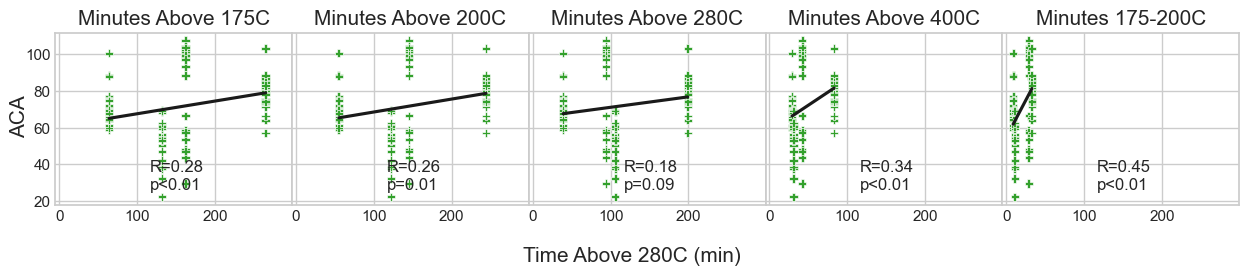

In [ ]:
# mask = ~(aca_temp_max_max_df['Type'].str.contains('Unburned'))
df = aca_temp_count_df.set_index(['Sample type','ACA per water droplet','Date','Sample','Type','rep','Depth']).stack().reset_index().rename(columns={'level_7':'Threshold',0:'Minutes'})

x='Minutes'
y = 'ACA per water droplet'

mask1 = (df['Type'].str.contains('Repellent') 
         & df['Depth'].str.contains('Surface'))
mask2 = (df['Type'].str.contains('3 cm') 
         & df['Depth'].str.contains('Surface'))
mask3 = (df['Type'].str.contains('6 cm') 
         & df['Depth'].str.contains('Surface'))
# mask4 = (df['Type'].str.contains('Charred') 
#          & df['Depth'].str.contains('Surface'))
# mask5 = (df['Type'].str.contains('Ash') 
#          & df['Depth'].str.contains('Surface'))
mask6 = df[x] == 0



# mask = ~(~(mask1 + mask2 + mask3 + mask4 + mask5) + mask6)
mask = mask1 + mask2 + mask3 #+ mask4 + mask5
mask = mask2



dict1 = {
    'Repellent layer':'Soil',
    '3 cm deep burned soil':'Soil',
    '6 cm deep burned soil':'Soil',
    'Charred layer':'Charred layer',
    'Ash':'Ash'
}

df = df[mask]
df['graph'] = df['Type'].map(dict1)






import warnings
warnings.filterwarnings('ignore')  # Suppress all warnings

g = sns.FacetGrid(df[mask], col='Threshold', #row='Depth',
                  #col_order=['Soil','Charred layer','Ash'],
                  row_order=['Surface','3 cm','6 cm'],
                  height=2.5, aspect=1,
                  margin_titles=True, despine=False)#, hue='rep')
g.map_dataframe(sns.regplot, x=x, y=y, scatter = False, color='k', ci=False)
g.map_dataframe(sns.scatterplot, x=x, y=y, hue='Type', style='Type', palette=sns.color_palette("Paired"),
                hue_order = ['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'],
                style_order = ['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil']
                )

g.set_axis_labels("", "")

g.fig.text(0.5, -0.06, 'Time Above 280C (min)', ha='center', va='center', size=15)
g.fig.text(0.01, 0.5, 'ACA', ha='center', va='center', rotation='vertical', size=15)


g.set_titles(row_template="{row_name}", col_template="{col_name}", size=15)
g.tick_params(
    axis='both',
    which='major',
    length=5,
    direction='in'
)

def annotate(data, **kws):
    r, p = stats.pearsonr(data[x], data['ACA per water droplet'])

    if (p<0.01):
        
        ax = plt.gca()
        ax.text(.4, .09, 'R={:.2f}\np<0.01'.format(r, p),
                transform=ax.transAxes)
    else:
        ax = plt.gca()
        ax.text(.4, .09, 'R={:.2f}\np={:.2f}'.format(r, p),
                transform=ax.transAxes)
    
g.map_dataframe(annotate)

g.set(xlim=(-5,299))

g.figure.subplots_adjust(wspace=0, hspace=0)

# g.add_legend()
# for ax in g.axes.flat:
#     for label in ax.get_xticklabels():
#         label.set_rotation(90)
plt.show()

# ACA vs Reflectance

In [14]:
aca_ref_df = aca_df.merge(ref_sample_df, on=['Date','Type','rep'])

aca_ref_df

NameError: name 'ref_sample_df' is not defined

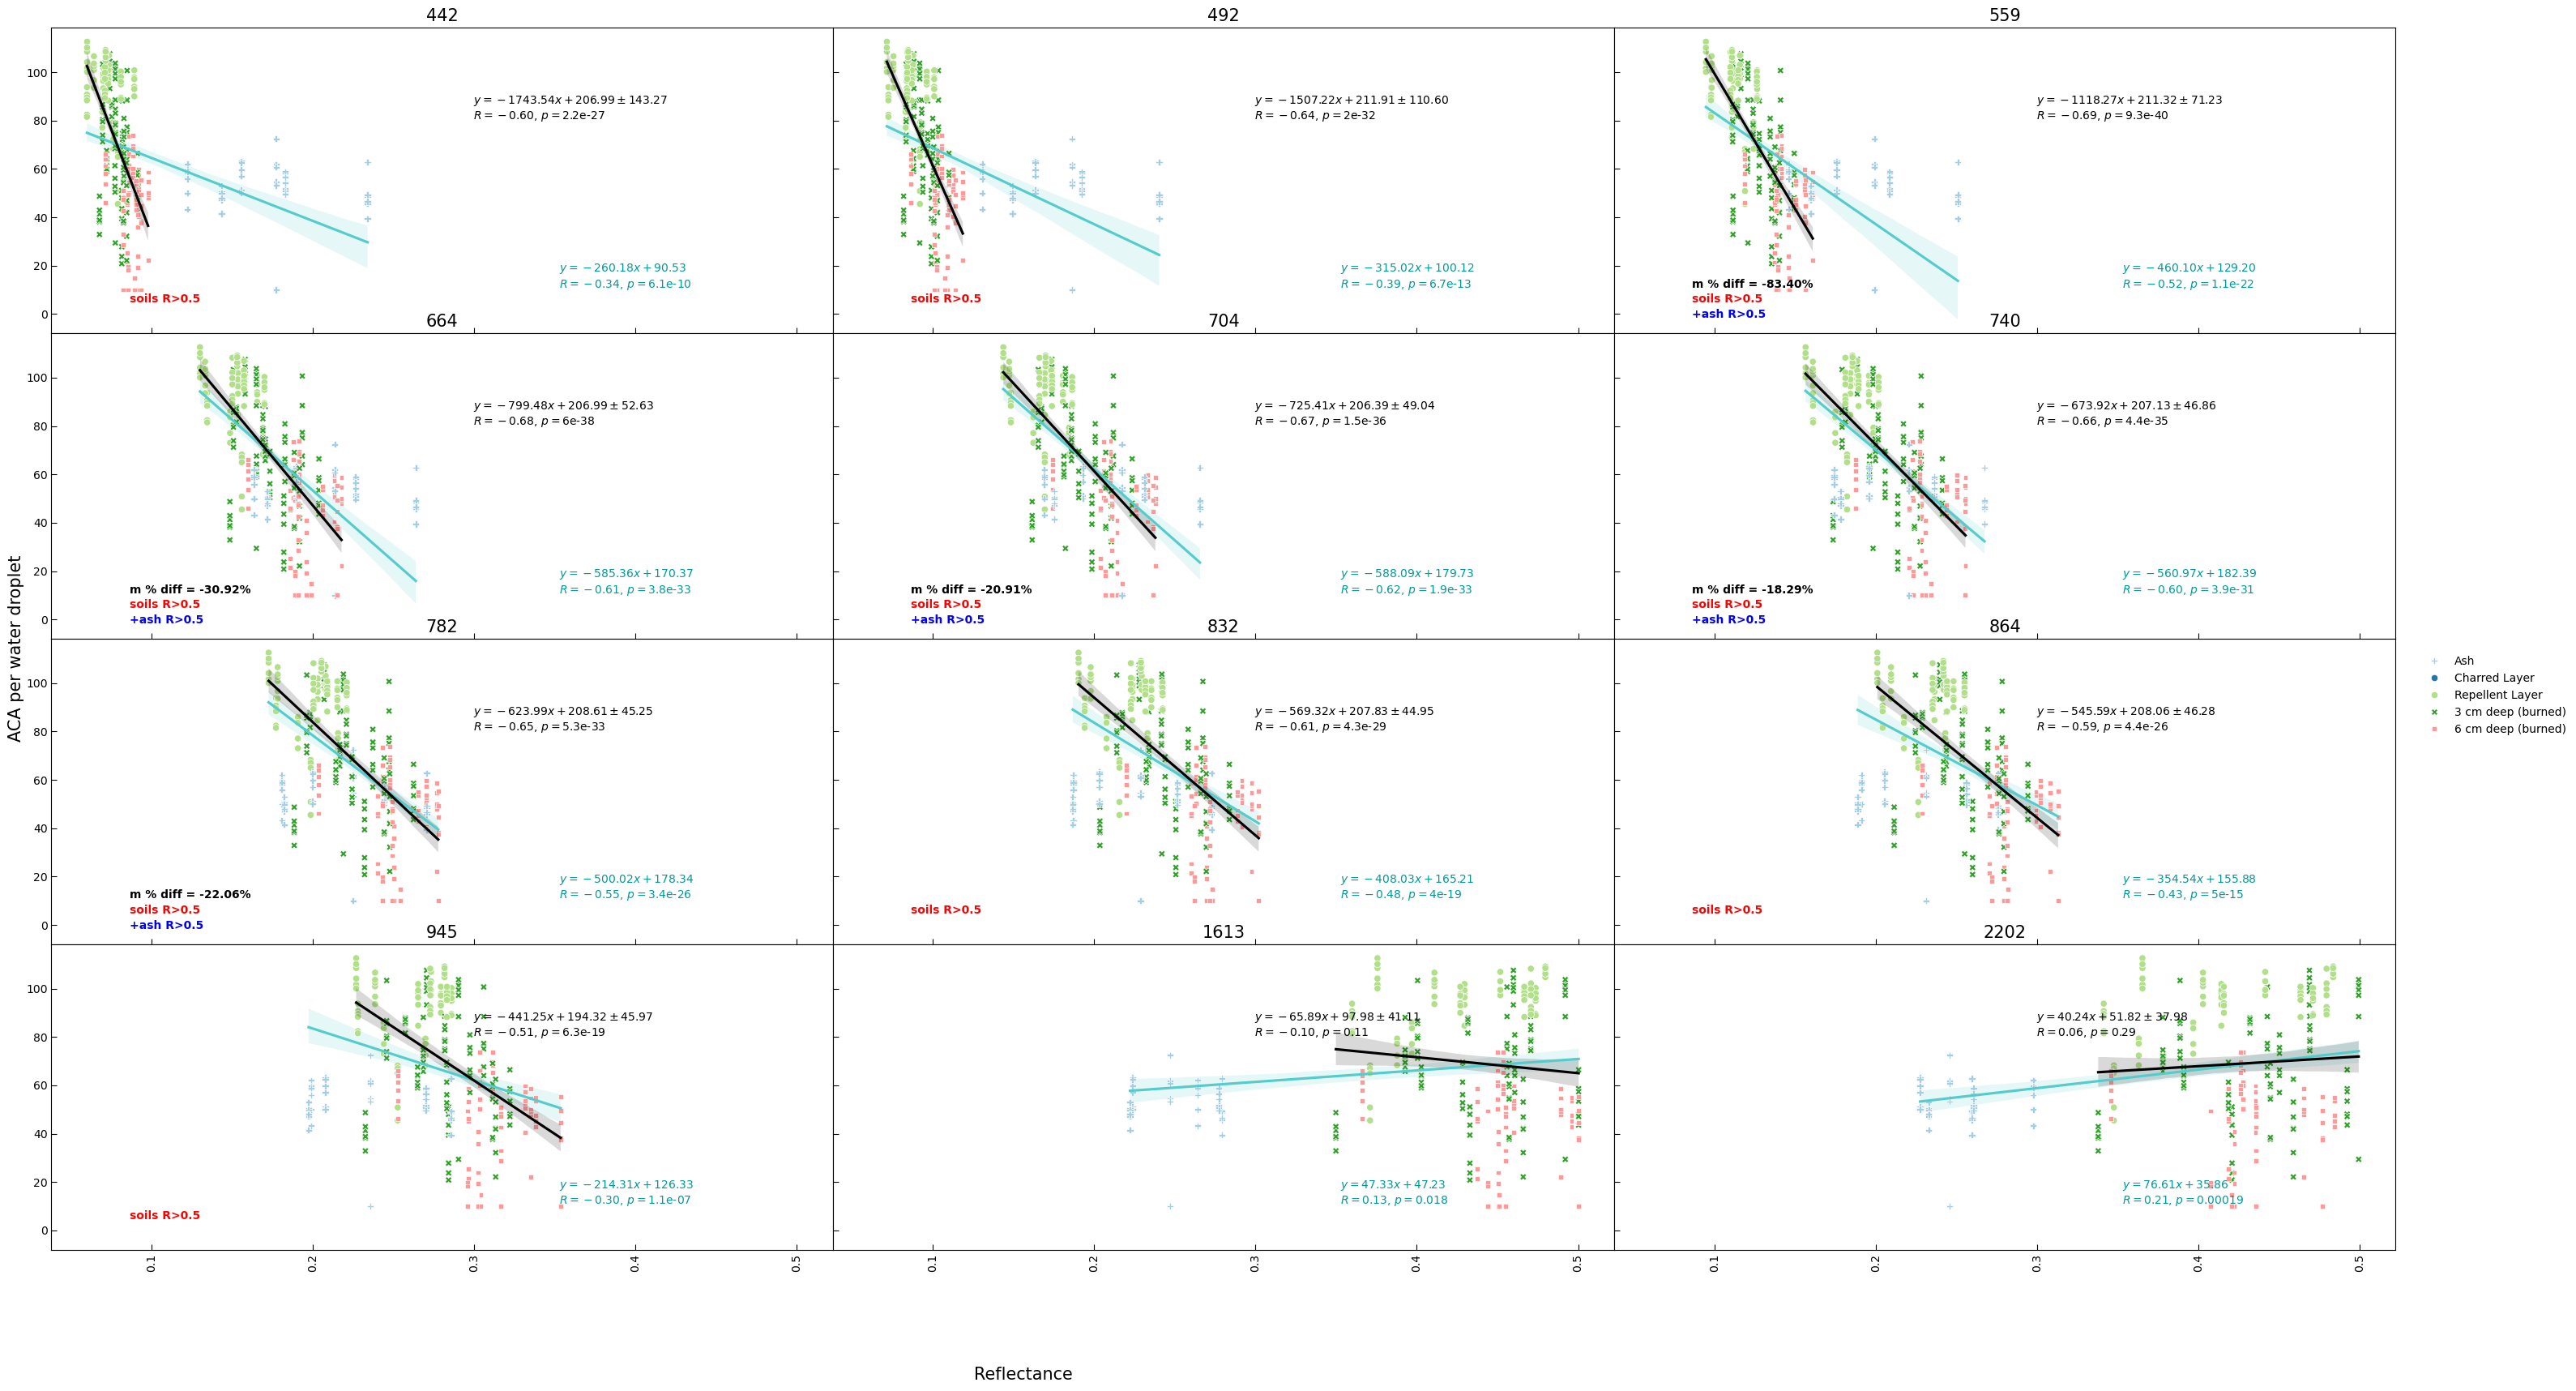

In [ ]:
df = aca_ref_df.copy()


mask1 = (df['Type'].str.contains('Repellent layer'))
mask2 = (df['Type'].str.contains('3 cm'))
mask3 = (df['Type'].str.contains('6 cm'))
mask4 = (df['Type'].str.contains('Ash'))

# mask4 = (df['Wavelength'] == 500)

mask = mask1 + mask2 + mask3 #+ mask4

maskb = mask1 + mask2 + mask3 + mask4

c = '#5cc'

x='Reflectance'
y='ACA per water droplet'


g = sns.FacetGrid(df[maskb],height=4, aspect=2.5, col='Wavelength', col_wrap = 3,
                  margin_titles=True, despine=False, sharex=True)#, hue='rep')
g.map_dataframe(sns.regplot, x=x, y=y, scatter = False, color=c)#, ci=None)
g.map_dataframe(sns.scatterplot, x=x, y=y, hue='Type',style='Type', 
                palette=sns.color_palette("Paired"), #'rocket'
                hue_order = ['Ash','Charred layer','Repellent layer','3 cm deep burned soil','6 cm deep burned soil'])


r_value_ash = 0
r_value_soils = 0

# Add a black reg line for best fit (no ash or charred)
def plot_filtered_regression(x, y, **kwargs):
    # 'data' is passed via kwargs when using FacetGrid.map_dataframe
    # Filter the data within the function scope for the current facet's data subset
    current_facet_data = kwargs.pop('data')
    subset_data = current_facet_data[mask]
    sns.regplot(x=x, y=y, data=subset_data, scatter=False, ax=plt.gca(), **kwargs)

g.map_dataframe(plot_filtered_regression, x=x, y=y, color='k')


# # Annotate black reg line (no ash or charred)
# def annotate(data, **kws):
#     # r, p = stats.pearsonr(data[mask]['NBR'], data[mask]['ACA per water droplet'])
#     slope, intercept, r_value, p_value, std_err = stats.linregress(data[mask][x], data[mask][y])

#     r_value_soils = r_value
#     slope_soils = slope

#     ax = plt.gca()
#     # ax.text(0.3, 0.27, 'r={:.2f}\np={:.2g}'.format(r, p),
#     #         transform=ax.transAxes)

#     ax.text(0.54,0.7, f'$y={slope:.2f}x{intercept:+.2f}\pm{std_err:.2f}$\n$R={r_value:.2f}$, $p=${p_value:.2g}',
#             transform=ax.transAxes)
#     if(r_value>0.5 or r_value<-0.5):
#         ax.text(0.1,0.1, 'soils R>0.5', color='r',weight='bold', transform=ax.transAxes)
    
# g.map_dataframe(annotate)



# Annotate blue reg line (all sample types)
def annotate(data, **kws):
    slope, intercept, r_value, p_value, std_err = stats.linregress(data[x], data[y])

    r_value_ash = r_value
    slope_ash = slope

    ax = plt.gca()

    ax.text(0.65,0.15, f'$y={slope:.2f}x{intercept:+.2f}$\n$R={r_value:.2f}$, $p=${p_value:.2g}',
            transform=ax.transAxes, color='#099')
    if(r_value>0.5 or r_value<-0.5):
        ax.text(0.1,0.05, '+ash R>0.5', color='b',weight='bold', transform=ax.transAxes)

    # r, p = stats.pearsonr(data[mask]['NBR'], data[mask]['ACA per water droplet'])
    slope, intercept, r_value, p_value, std_err = stats.linregress(data[mask][x], data[mask][y])

    r_value_soils = r_value
    slope_soils = slope

    ax = plt.gca()
    # ax.text(0.3, 0.27, 'r={:.2f}\np={:.2g}'.format(r, p),
    #         transform=ax.transAxes)

    ax.text(0.54,0.7, f'$y={slope:.2f}x{intercept:+.2f}\pm{std_err:.2f}$\n$R={r_value:.2f}$, $p=${p_value:.2g}',
            transform=ax.transAxes)
    if(r_value>0.5 or r_value<-0.5):
        ax.text(0.1,0.1, 'soils R>0.5', color='r',weight='bold', transform=ax.transAxes)
    
    if (abs(r_value_ash) > 0.5 and abs(r_value_soils) > 0.5):
        ax.text(0.1,0.15, f'm % diff = {(slope_ash-slope_soils)/((slope_soils+slope_ash)/2):.2%}', color='k',weight='bold', transform=ax.transAxes)
    
g.map_dataframe(annotate)



g.set_axis_labels("", "")

g.fig.text(0.4, -0.06, x, ha='center', va='center', size=15)
g.fig.text(0.01, 0.5, y, ha='center', va='center', rotation='vertical', size=15)

g.set_titles(row_template="{row_name}", col_template="{col_name}", size=15)

g.tick_params(
    axis='both',
    which='major',
    length=5,
    direction='in'
)


g.figure.subplots_adjust(wspace=0, hspace=0)



for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(90)


g.add_legend()

plt.show()

# Comparison with Asner and Heidebrecht

In [64]:
sorted_dic['green']['green_samplemeans'] / sorted_dic['green']['green_samplemeans'].loc[2030]

,Jul14-green-1,Jul14-green-2,Jul14-green-3,Jul15-green-1,Jul15-green-2,Jul15-green-3,Jul16-green-1,Jul17-green-1,Jul17-green-2,Jul17-green-3,Jul18-green-1,Jul18-green-2,Jul18-green-3,mean,std
Wavelength,,,,,,,,,,,,,,,
350.0,0.120730,0.107480,0.146387,0.104884,0.103316,0.104919,0.160104,0.103295,0.100227,0.100165,0.094421,0.095225,0.097177,0.109735,0.156777
351.0,0.120418,0.107689,0.147080,0.104987,0.103608,0.104452,0.159844,0.104523,0.100190,0.101386,0.094368,0.094606,0.096636,0.109842,0.156663
352.0,0.120795,0.107665,0.147308,0.105879,0.104121,0.104599,0.160602,0.105192,0.101580,0.101749,0.094744,0.095161,0.097452,0.110404,0.157477
353.0,0.120904,0.107556,0.147298,0.106372,0.103733,0.104798,0.161097,0.104713,0.102366,0.101039,0.094988,0.095764,0.098026,0.110559,0.158488
354.0,0.120165,0.107513,0.147473,0.105896,0.102376,0.104606,0.160545,0.103773,0.101612,0.100150,0.094728,0.095444,0.097254,0.110005,0.158865
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2496.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2497.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2498.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


blue [0, 1]
green [0, 1, 2]
grey [0, 2]
pink [0, 1]
white [0, 2]
below2in [0]
top2in [0, 2]


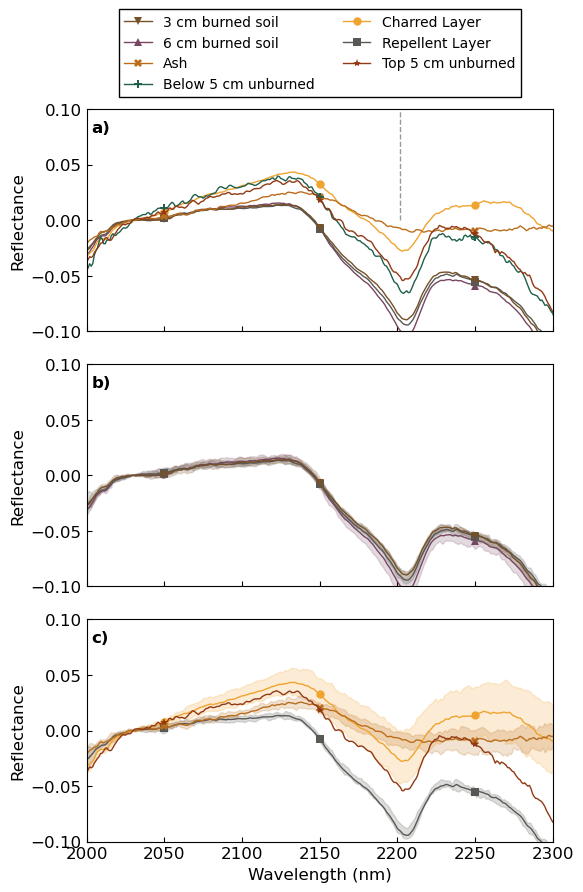

In [ ]:
pal = ['#774762FF', '#BA6E1DFF', '#D6BB3BFF', '#755028FF', '#F2DD78FF', '#205F4BFF', '#913914FF', '#585854FF', '#F0A430FF', '#768048FF', '#800000FF', '#1B3A54FF']


lineformats_t = {
                'blue':[pal[0],'6 cm deep burned soil','^'],
               'green':[pal[7],'Repellent layer', 's'],
               'grey':[pal[8],'Charred layer','o'],
               'pink':[pal[3],'3 cm deep burned soil', 'v'],
               'white':[pal[1],'Ash', 'X'],
               'below2in':[pal[5],'Below 5 cm unburned','P'],
               'top2in':[pal[6],'Top 5 cm unburned','*']
               }


a = f'D_split'
plt.style.use(style_default)
plt.rcParams.update({'font.size': 12})

fig, axes = plt.subplots(3,1, figsize=(6,9), # change to 4,1, figsize=(6,9.6) when only 4 main sample types; 5,1, figsize=(6,12) otherwise
                        layout="tight", sharex=True, sharey=True
                        )

# fig.suptitle(f"Standard Error of All Samples")
# fig.supxlabel("Wavelength (nm)")
axes[2].set_xlabel("Wavelength (nm)")


sorted_dic_tied = {}

for my_type,sample_list in sorted_dic.items():
    sorted_dic_tied[my_type] = {}
    sorted_dic_tied[my_type][f'{my_type}_samplemeans'] = sorted_dic[my_type][f'{my_type}_samplemeans'] / sorted_dic[my_type][f'{my_type}_samplemeans'].loc[2030] -1

for type,sample_list in sorted_dic_tied.items():
    drop_rows(sorted_dic_tied[type][f'{type}_samplemeans'])
    i_list = []

    if type in ['white','green','grey','pink','blue','top2in','below2in']:
        i_list.append(0)
    if type in ['blue','pink','green']:
        i_list.append(1)
    if type in ['top2in','green','white', 'grey']:
        i_list.append(2)
    # if type in ['pink','green']:
    #     i_list.append(3)

    print(type,i_list)

    df = mean_quartile_col(sample_list[f'{type}_samplemeans'])
    drop_rows(df)



    if len(i_list) > 0:
        for i in i_list:
            
            # Set axis titles:
            axes[i].set_ylim(0,1)
            axes[i].set_ylabel("Reflectance")
            axes[i].set_xlim(350,2500)
            axes[i].tick_params(direction="in")
        
            line, = axes[i].plot(df['mean'],
                        linewidth=1, # default line width. Consider going smaller
                        color=lineformats_t[type][0], markevery=100
                        )
            line.set_label(lineformats_t[type][1])
            line.set_marker(lineformats_t[type][2])
            line.set_markeredgewidth(0)
            # line.set_markersize(3)


        # Plot std deviation as error envelope
            if (i != 0):
                axes[i].fill_between(df.index, df['1st'], df['3rd'],
                                # df['mean'] - df['std'], 
                                # df['mean'] + df['std'], 
                                color=lineformats_t[type][0], alpha=0.2)
            
            # axes[i].legend(fontsize='x-small',fancybox=False,shadow=False,
            #             loc='upper left',
            #             frameon=False,
            #             #   framealpha=1,edgecolor="black"
            #             )

i=0

for ax in axes:

    
    
    ax.text(s=f'{letters[i]})', x=0.01,y=0.95,transform=ax.transAxes, weight='bold',
                    fontsize='medium', verticalalignment='top', fontfamily='sans serif'
                    # bbox=dict(facecolor='0.7', edgecolor='none', pad=3.0)
                )
    
    i+=1

ax = axes[0]
handles, labels = ax.get_legend_handles_labels()
sorted_labels_handles = sorted(zip(labels, handles), key=lambda x: x[0])
sorted_labels = [item[0] for item in sorted_labels_handles]
sorted_handles = [item[1] for item in sorted_labels_handles]

# 4. Pass the sorted handles and labels to ax.legend()
ax.legend(sorted_handles, sorted_labels,fancybox=False,shadow=False, ncols=2,fontsize=10,
                    loc='upper center', bbox_to_anchor=(0.5, 1.481),#bbox_to_anchor=(0.042, 0.981),
                    facecolor='w', edgecolor='k', framealpha=1)


for w in wavelengths:
    axes[0].vlines(w, ymin=0,ymax=1,color='#0006', linestyle='--', linewidth=1)


axes[1].set_ylim(-0.1,0.1)
axes[1].set_xlim(2000,2300)
fig.tight_layout()

# savefig('Spectra.svg')

# Comparison against Okin, et al., 2001

In [90]:
sorted_dic_SER['blue']['blue_samplemeans']['mean']

Wavelength
350.0     11.153468
351.0     11.259901
352.0     11.399260
353.0     11.415295
354.0     11.326180
            ...    
2496.0          NaN
2497.0          NaN
2498.0          NaN
2499.0          NaN
2500.0          NaN
Name: mean, Length: 2151, dtype: float64

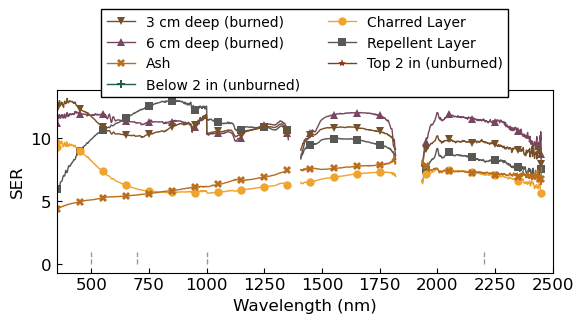

In [ ]:
pal = ['#774762FF', '#BA6E1DFF', '#D6BB3BFF', '#755028FF', '#F2DD78FF', '#205F4BFF', '#913914FF', '#585854FF', '#F0A430FF', '#768048FF', '#800000FF', '#1B3A54FF']


lineformats_t = {
                'blue':[pal[0],'6 cm deep burned soil','^'],
               'green':[pal[7],'Repellent layer', 's'],
               'grey':[pal[8],'Charred layer','o'],
               'pink':[pal[3],'3 cm deep burned soil', 'v'],
               'white':[pal[1],'Ash', 'X'],
               'below2in':[pal[5],'Below 5 cm unburned','P'],
               'top2in':[pal[6],'Top 5 cm unburned','*']
               }


a = f'D_split'
plt.style.use(style_default)
plt.rcParams.update({'font.size': 12})

fig, axes = plt.subplots(1,1, figsize=(6,4), # change to 4,1, figsize=(6,9.6) when only 4 main sample types; 5,1, figsize=(6,12) otherwise
                        layout="tight",
                        )

# fig.suptitle(f"Standard Error of All Samples")
# fig.supxlabel("Wavelength (nm)")
axes.set_xlabel("Wavelength (nm)")


sorted_dic_SER = {}

for my_type,sample_list in sorted_dic.items():
    sorted_dic_SER[my_type] = {}
    sorted_dic_SER[my_type][f'{my_type}_samplemeans'] = sorted_dic[my_type][f'{my_type}_samplemeans'].divide(sorted_dic[my_type][f'{my_type}_samplemeans']['std'], axis=0)

for type,sample_list in sorted_dic_SER.items():
    # drop_rows(sorted_dic_SER[type][f'{type}_samplemeans'])



    axes.set_ylabel("SER")
    axes.set_xlim(350,2500)
    axes.tick_params(direction="in")

    line, = axes.plot(sample_list[f'{type}_samplemeans']['mean'],
                linewidth=1, # default line width. Consider going smaller
                color=lineformats_t[type][0], markevery=100
                )
    line.set_label(lineformats_t[type][1])
    line.set_marker(lineformats_t[type][2])
    line.set_markeredgewidth(0)


handles, labels = axes.get_legend_handles_labels()
sorted_labels_handles = sorted(zip(labels, handles), key=lambda x: x[0])
sorted_labels = [item[0] for item in sorted_labels_handles]
sorted_handles = [item[1] for item in sorted_labels_handles]

# Pass the sorted handles and labels to ax.legend()
axes.legend(sorted_handles, sorted_labels,fancybox=False,shadow=False, ncols=2,fontsize=10,
                    loc='upper center', bbox_to_anchor=(0.5, 1.481),#bbox_to_anchor=(0.042, 0.981),
                    facecolor='w', edgecolor='k', framealpha=1)


# for w in wavelengths:
#     axes.vlines(w, ymin=0,ymax=1,color='#0006', linestyle='--', linewidth=1)


# axes[1].set_ylim(-0.1,0.1)
# axes[1].set_xlim(2000,2300)
fig.tight_layout()

savefig('Spectra.svg')